In [100]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [101]:
import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

In [340]:
from scripts_.stitching_vk_data import plot_stitched_height_image_from_vk #, plot_stitched_height_image_from_vk_2
from scripts_.tilt_correction import baseplane_filter, plot_baseplane
from scripts_.plot_vk_data import plot_vk4_height, plot_vk4_reflected_light, reshape_img_data
from scripts_.load_vk_data import parse_vk6_file, parse_vk4_file
from scripts_.preprocess_vk_data import crop_Vk4File_map
from scripts_.feature_enhancement import gaussian_filter_height, feature_enhancement_proceedings, feature_enhancement_single_gaussian_clip, feature_enhancement_double_gaussian_clip, feature_enhancement_triple_gaussian_clip, feature_enhancement_single_gaussian_median_clip, feature_enhancement_double_gaussian_median_clip, feature_enhancement_median_clip_high, feature_enhancement_cut_elevations_and_holes, feature_enhancement_cut_elevations_and_holes_2, feature_enhancement_morphological, feature_enhancement_diff_gaussians, feature_enhancement_stretch_contrast
import numpy as np
import matplotlib.pyplot as plt
import itertools
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter

**Compare different percentages for tilt correction**


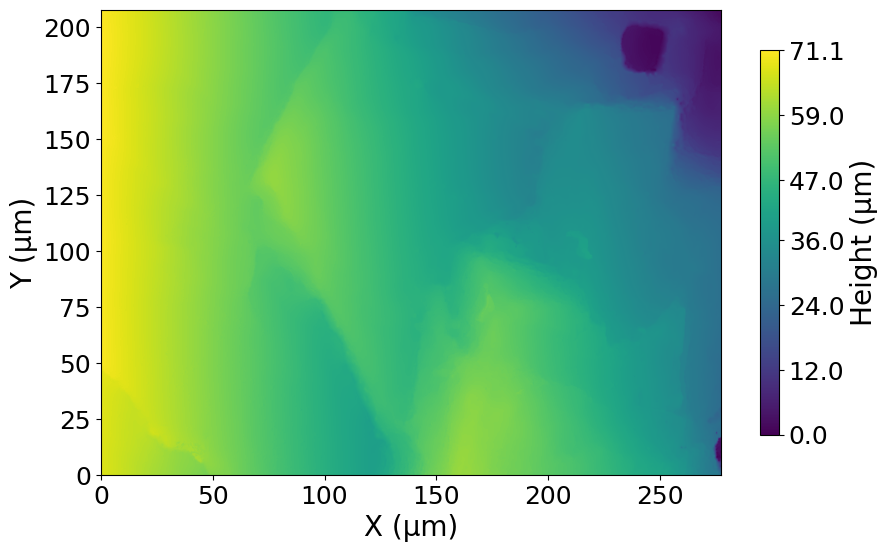

In [549]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y3_X2.vk4")

with open(file_name, 'rb') as f:
    data_1_vk4 = parse_vk4_file(f)

ax = plot_vk4_height(data_1_vk4, data_type='original')

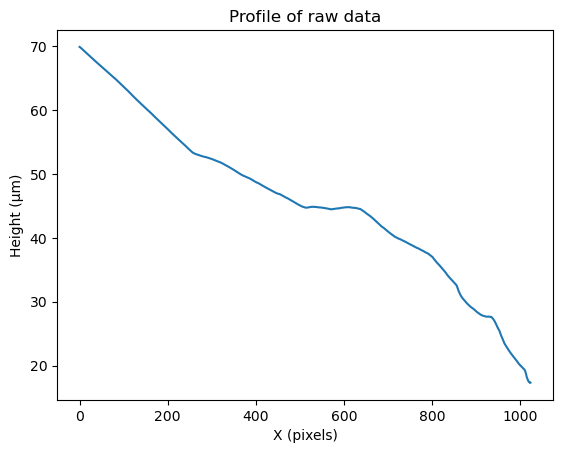

In [550]:
reshaped = reshape_img_data(data_1_vk4)
profile = np.mean(reshaped, axis=0) #nanmedian
x_pixels = reshaped.shape[1]
#y_pixels = reshaped.shape[0]

#for i in range(1, y_pixels, 400):
plt.plot(range(x_pixels), profile)#reshaped[i])
plt.title('Profile of raw data')
plt.xlabel('X (pixels)')
plt.ylabel('Height (µm)')
plt.show()

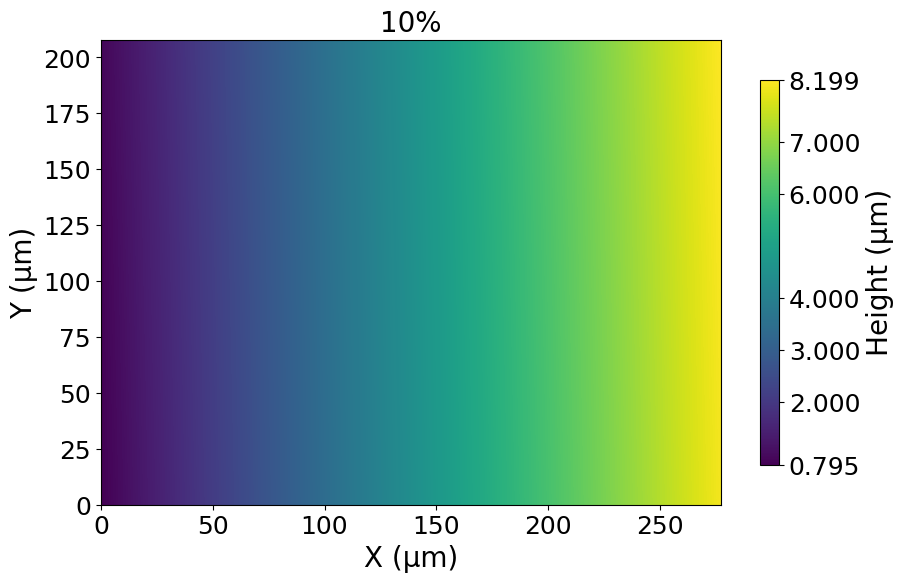

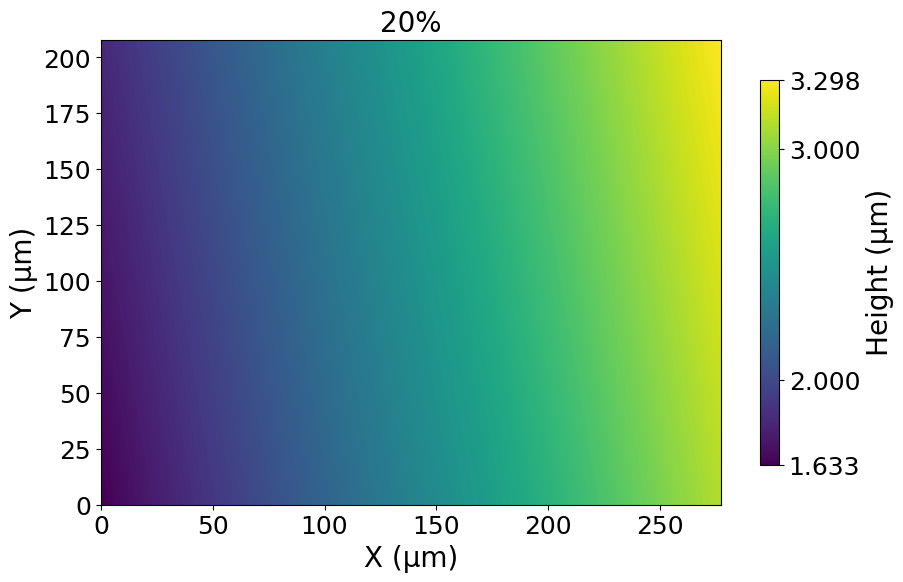

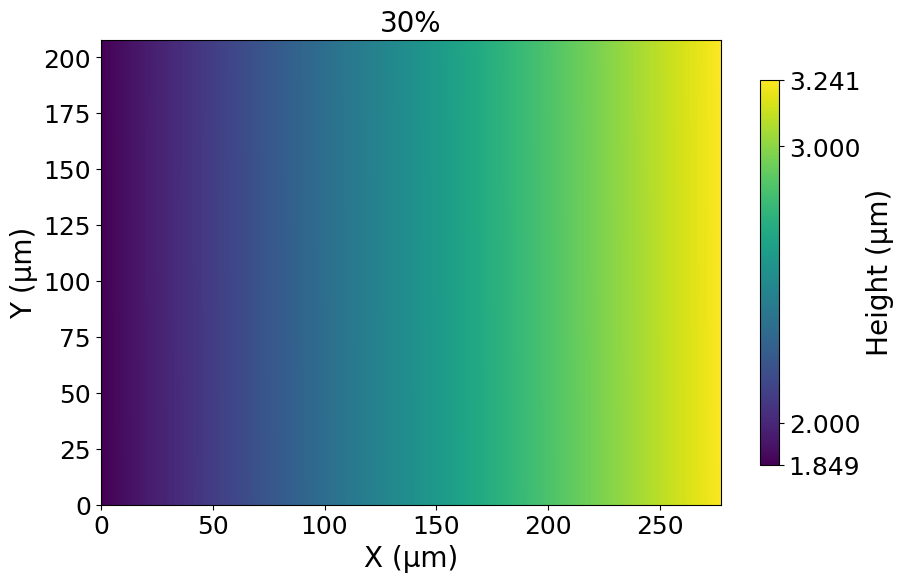

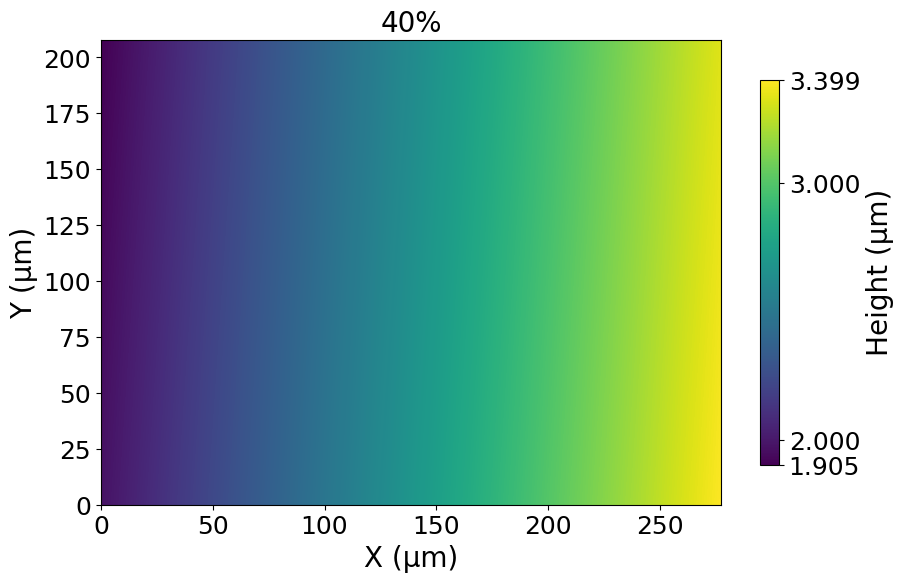

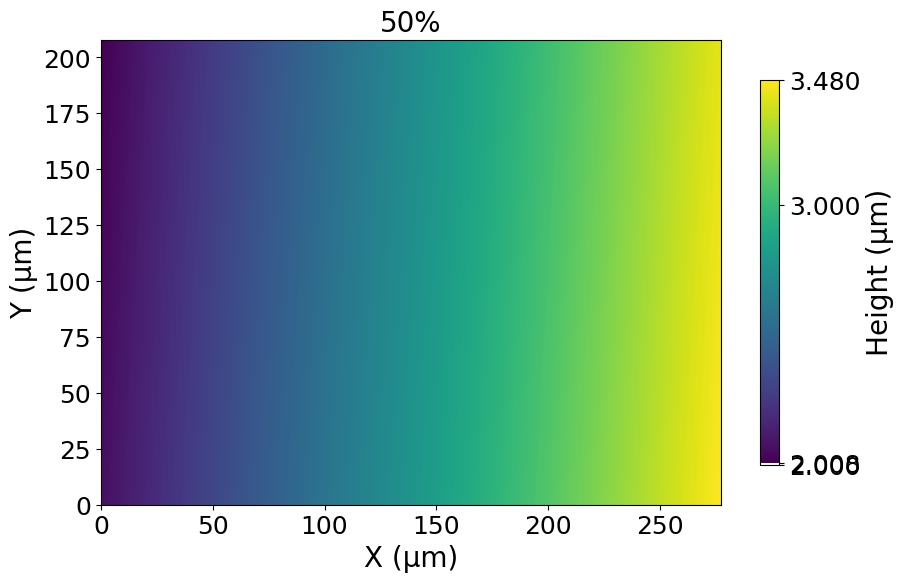

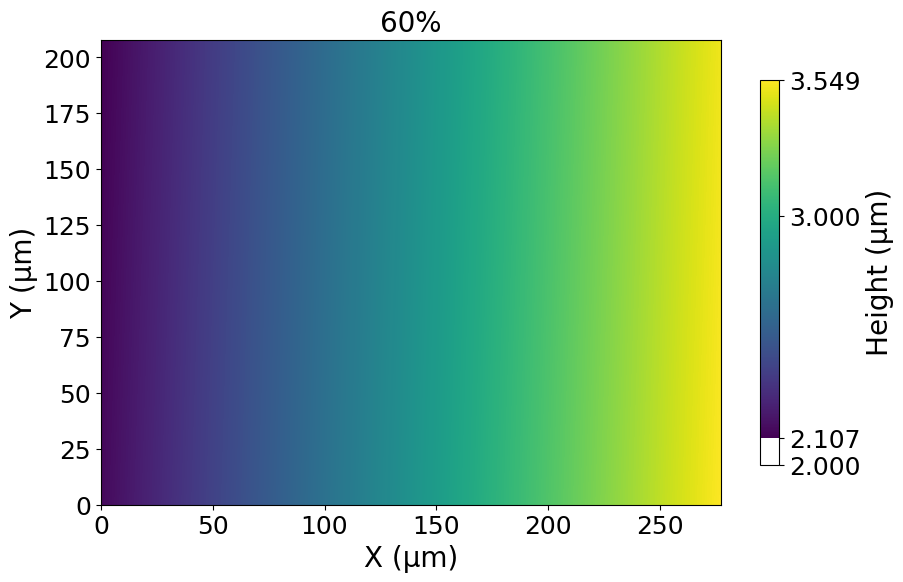

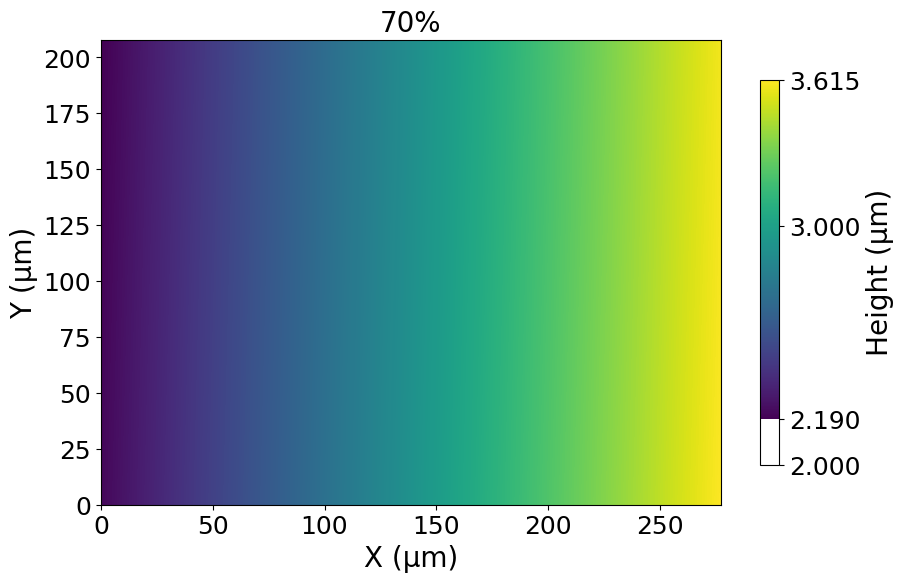

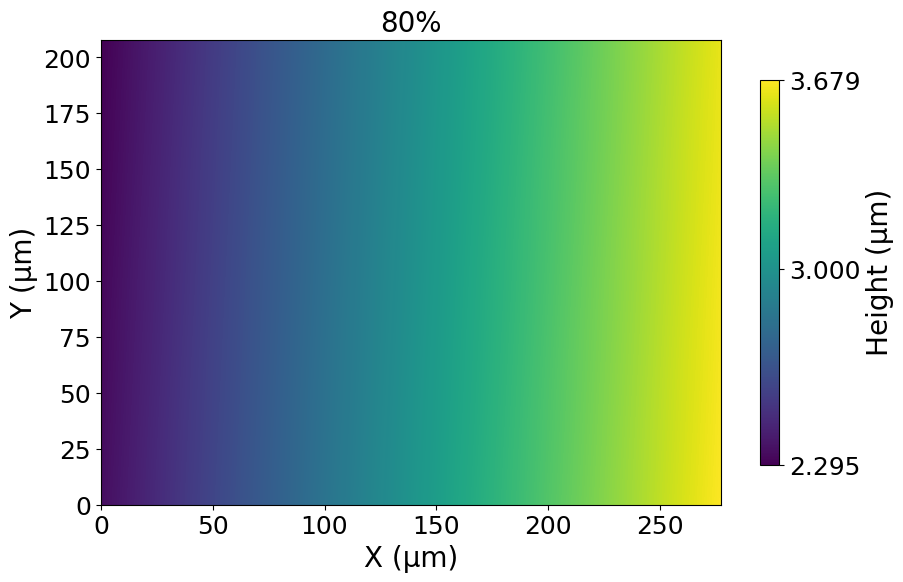

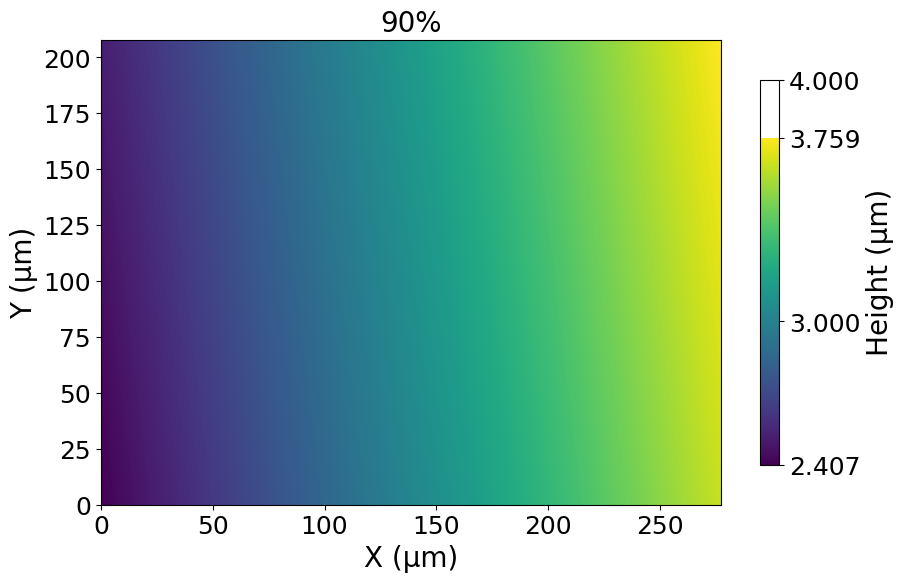

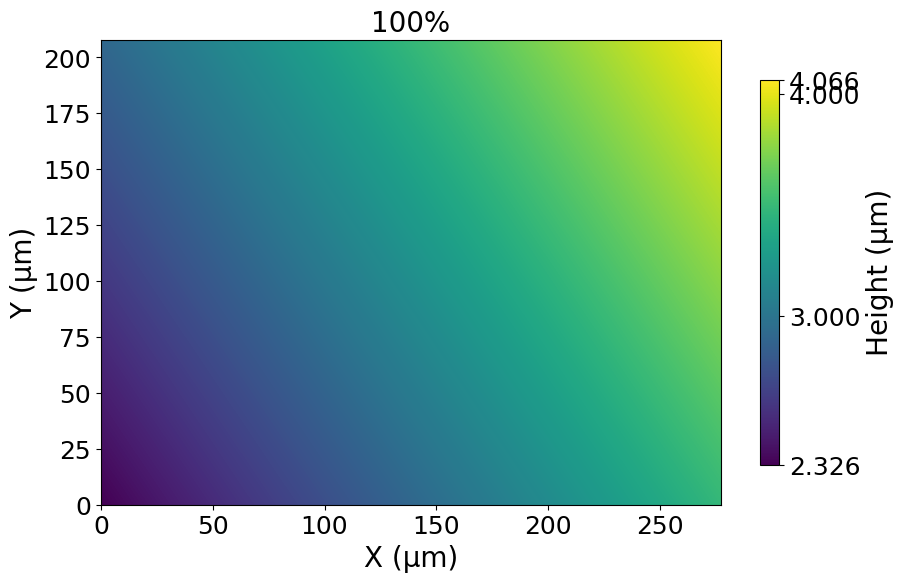

In [470]:
percentages = np.arange(10, 110, 10)

for percentage in percentages:
    data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, percentage)
    
    ax = plot_vk4_height(data_1_vk4_tiltcorr, data_type='baseplane_fit')
    ax.set_title(f'{percentage}%', fontsize=20)

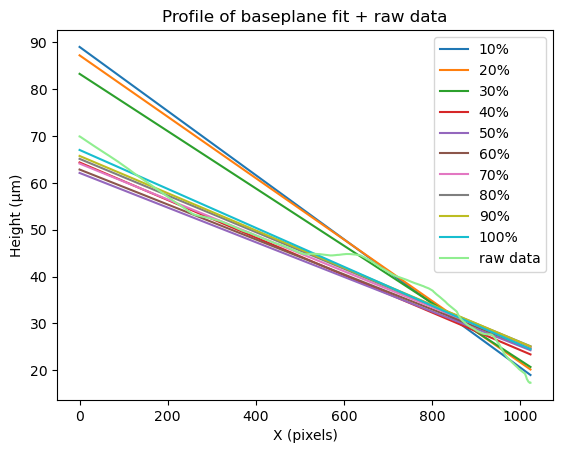

In [551]:
for percentage in percentages:
    data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, percentage)
    reshaped = reshape_img_data(data_1_vk4_tiltcorr, data_type='baseplane_fit')
    profile2 = np.mean(reshaped, axis=0) #nanmedian
    x_pixels = reshaped.shape[1]    
    plt.plot(range(x_pixels), profile2, label=f'{percentage}%')
plt.plot(range(x_pixels), profile, color='lightgreen', label='raw data')
plt.title('Profile of baseplane fit + raw data')
plt.xlabel('X (pixels)')
plt.ylabel('Height (µm)')
plt.legend()
plt.show()

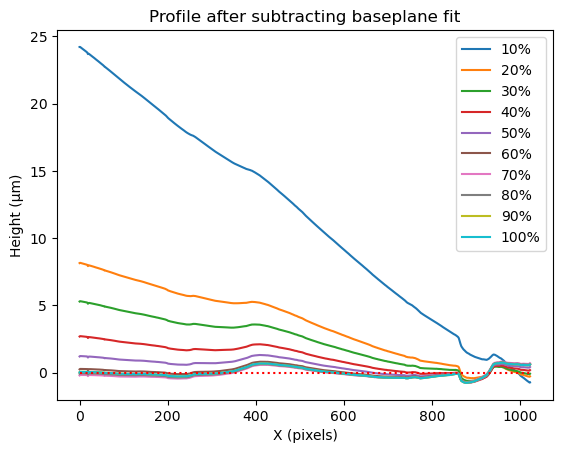

In [525]:
percentages = np.arange(10, 110, 10)

for percentage in percentages:
    data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, percentage)
    reshaped = reshape_img_data(data_1_vk4_tiltcorr, data_type='baseplane_subtracted')
    profile_baseplane = np.mean(reshaped, axis=0)
    x_pixels = reshaped.shape[1]
    plt.plot(range(x_pixels), profile_baseplane, label=f'{percentage}%')

plt.hlines(0, 0, 1024, 'red', 'dotted')
plt.legend()
plt.title('Profile after subtracting baseplane fit')
plt.xlabel('X (pixels)')
plt.ylabel('Height (µm)')
plt.show()

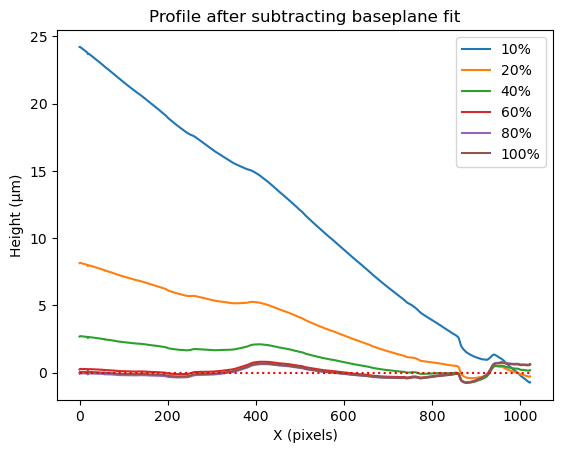

In [527]:
percentages2 = [10, 20, 40, 60, 80, 100]

for percentage in percentages2:
    data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, percentage)
    reshaped = reshape_img_data(data_1_vk4_tiltcorr, data_type='baseplane_subtracted')
    profile_baseplane = np.mean(reshaped, axis=0)
    x_pixels = reshaped.shape[1]
    plt.plot(range(x_pixels), profile_baseplane, label=f'{percentage}%')
    
plt.xlabel('X (pixels)')
plt.ylabel('Height (µm)')
plt.legend()
plt.title('Profile after subtracting baseplane fit')
plt.hlines(0, 0, 1024, 'red', 'dotted')
plt.show()

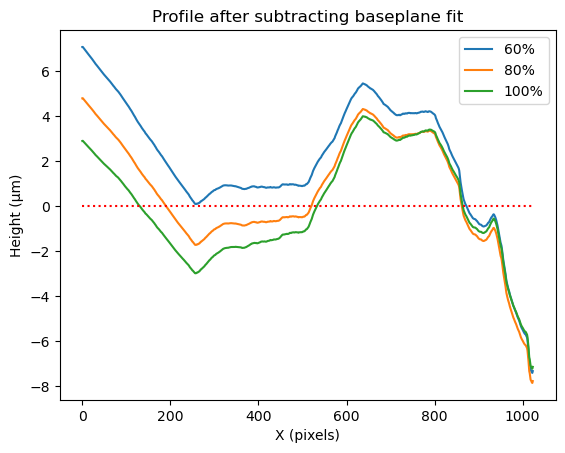

In [552]:
percentages3 = [60, 80, 100]

for percentage in percentages3:
    data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, percentage)
    reshaped = reshape_img_data(data_1_vk4_tiltcorr, data_type='baseplane_subtracted')
    profile_baseplane = np.mean(reshaped, axis=0)
    x_pixels = reshaped.shape[1]
    plt.plot(range(x_pixels), profile_baseplane, label=f'{percentage}%')
    
plt.xlabel('X (pixels)')
plt.ylabel('Height (µm)')
plt.legend()
plt.title('Profile after subtracting baseplane fit')
plt.hlines(0, 0, 1024, 'red', 'dotted')
plt.show()

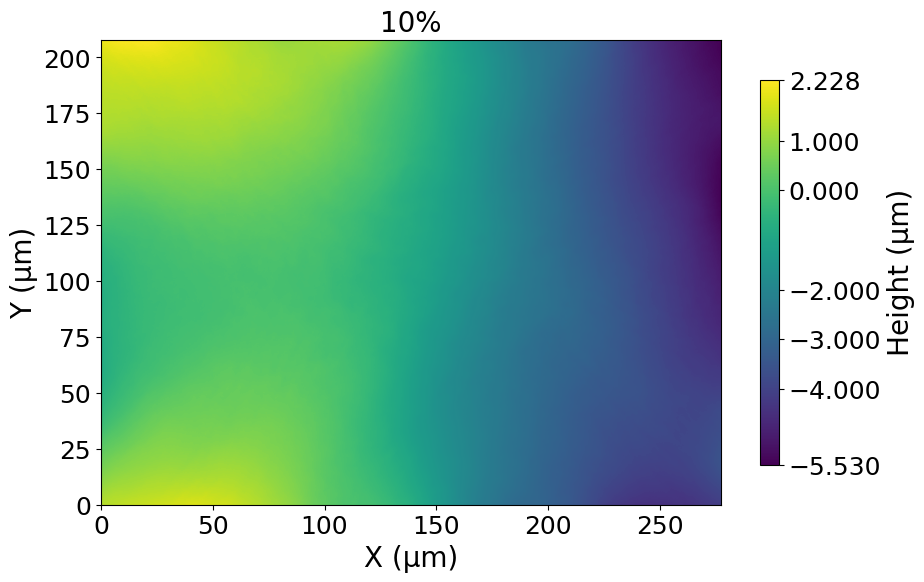

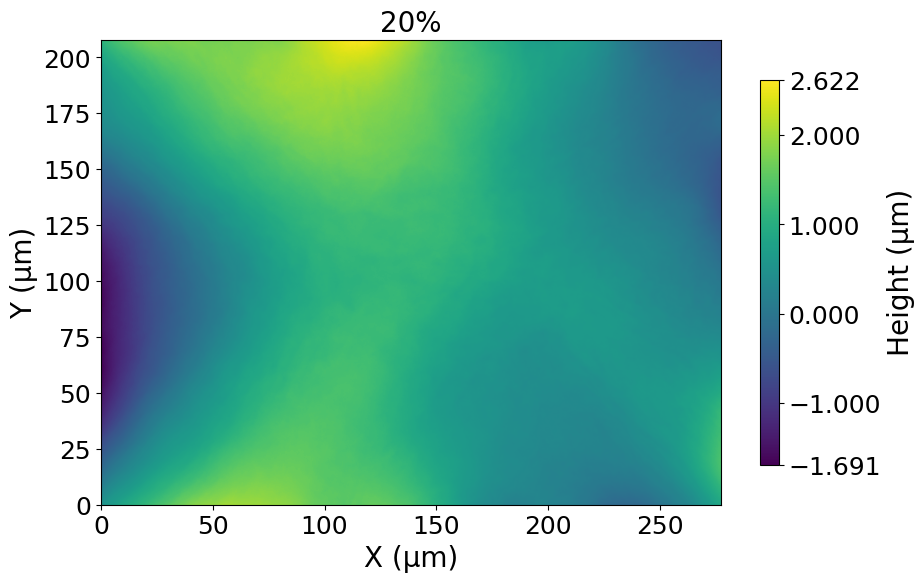

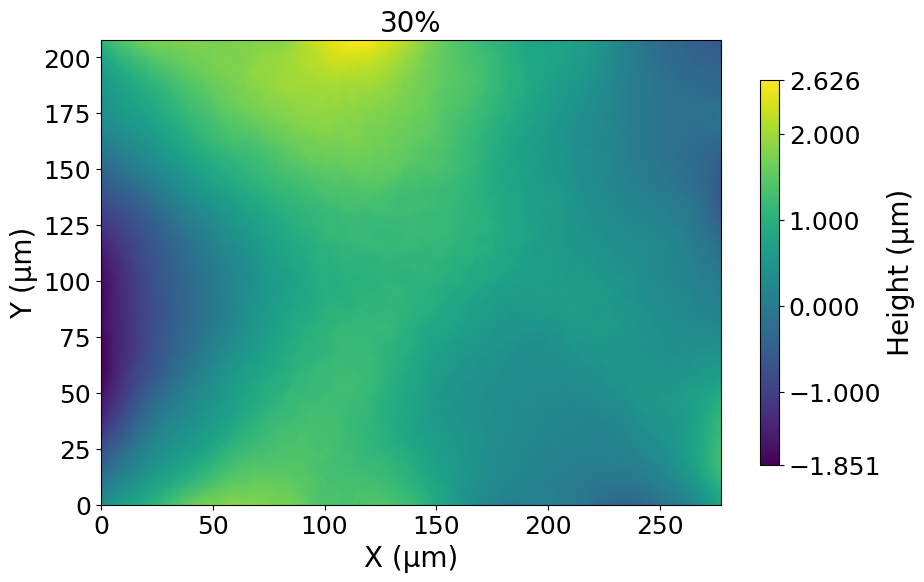

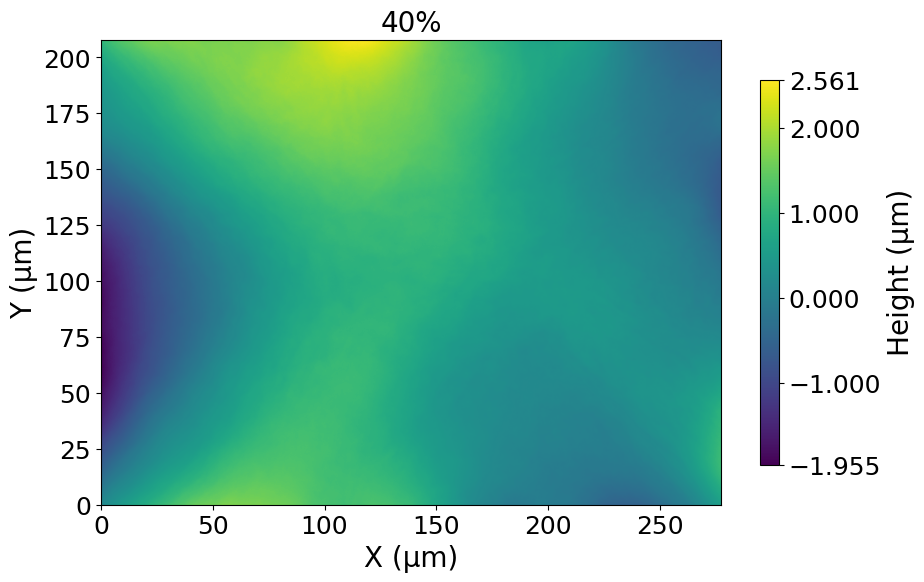

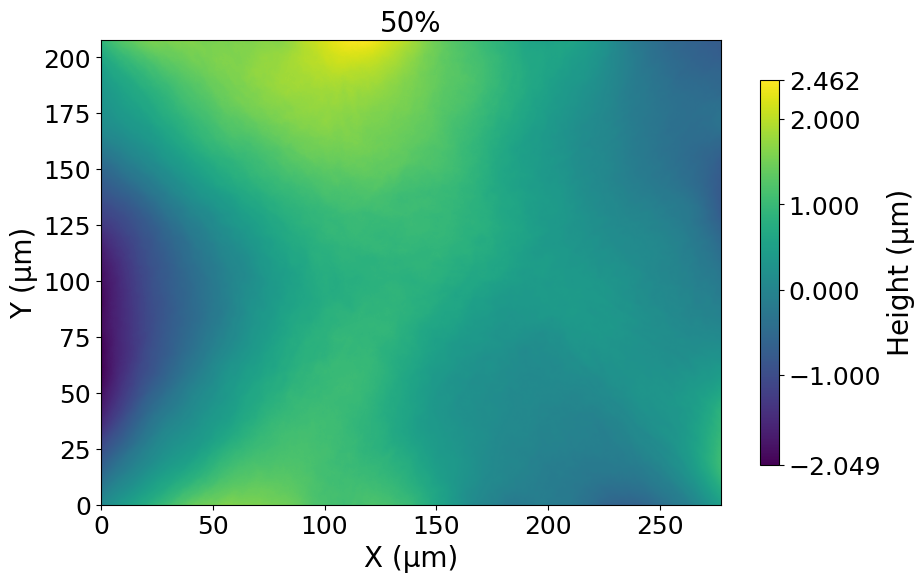

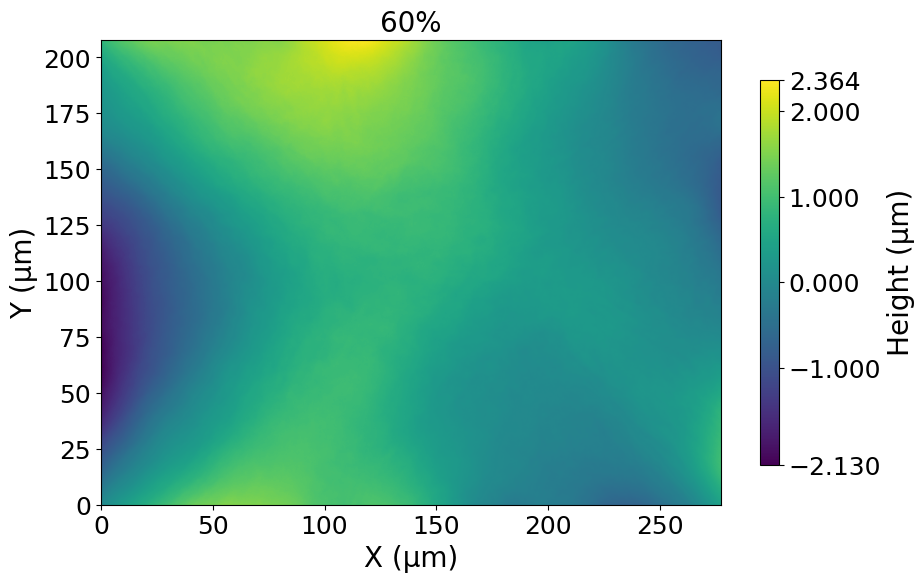

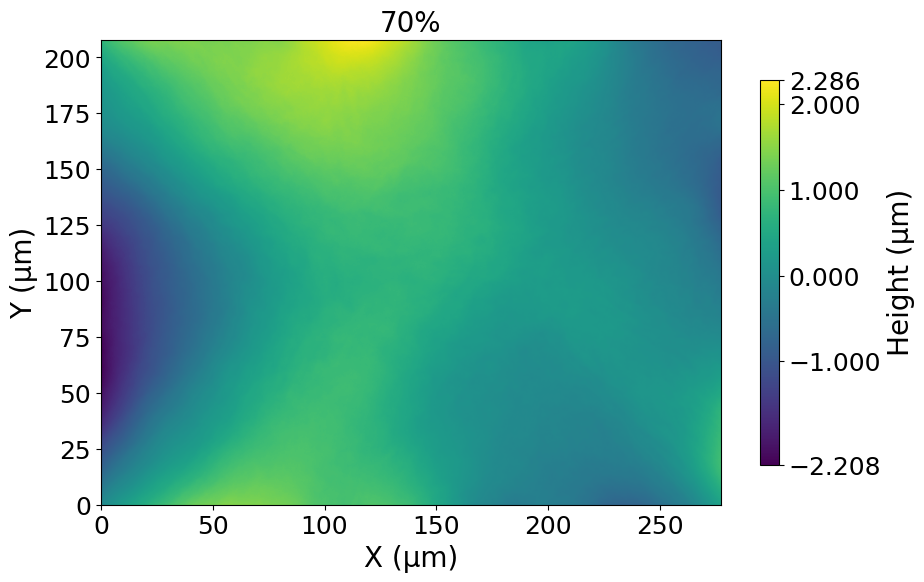

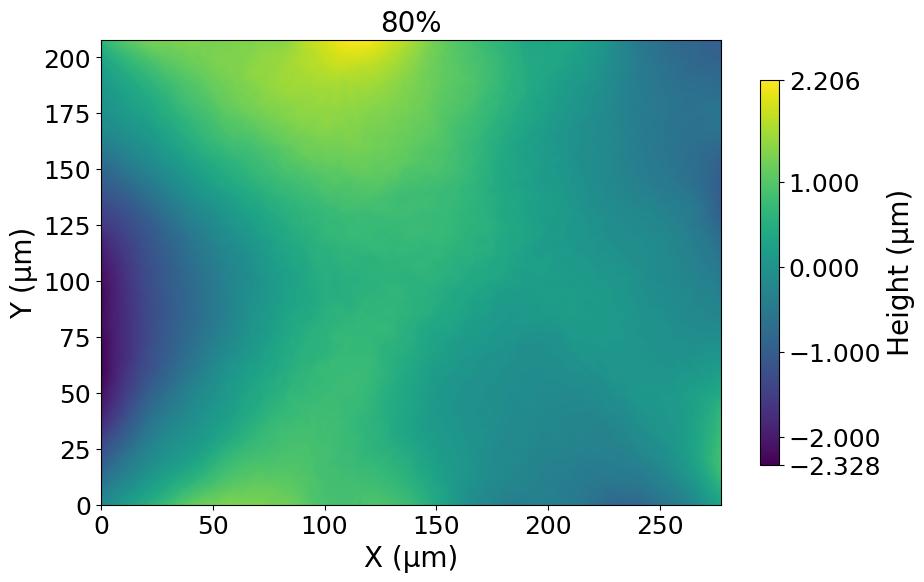

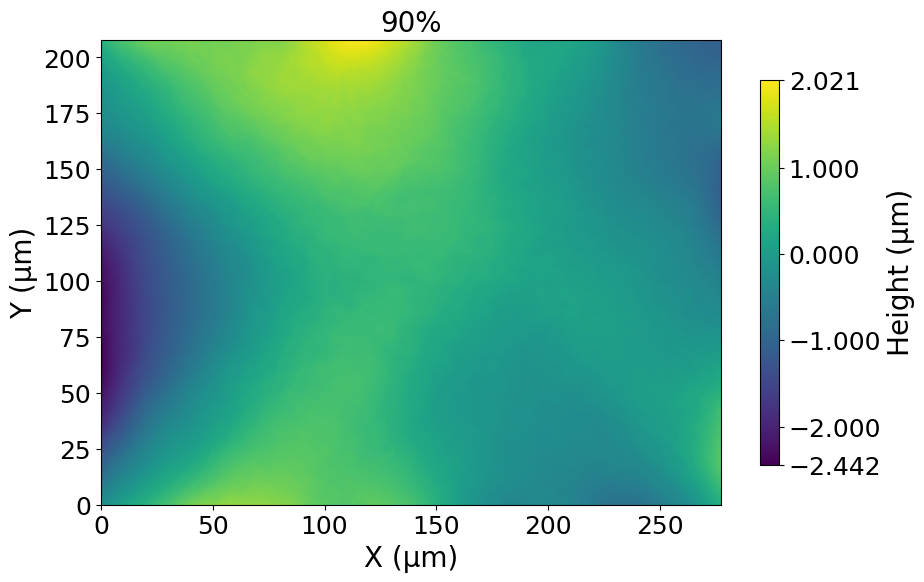

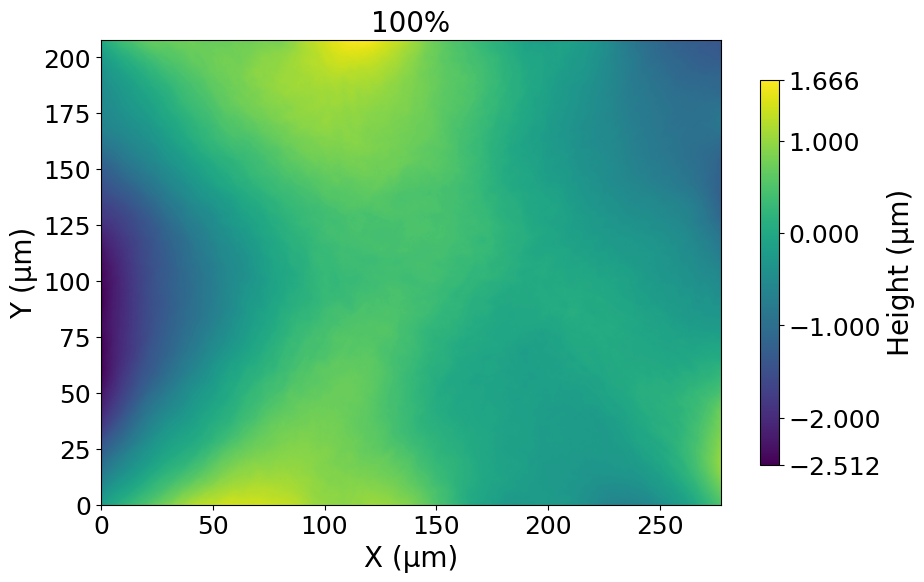

In [ ]:
height_data = []
height_min = []
height_max = []
height_range = []

for percentage in percentages:
    data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, percentage)
    height_data.append(np.array(data_1_vk4_tiltcorr['baseplane_subtracted'].flatten()))
    height_min.append(np.min(data_1_vk4_tiltcorr['baseplane_subtracted']))
    height_max.append(np.max(data_1_vk4_tiltcorr['baseplane_subtracted']))
    height_range.append(np.max(data_1_vk4_tiltcorr['baseplane_subtracted']) + np.abs(np.min(data_1_vk4_tiltcorr['baseplane_subtracted'])))
    ax = plot_vk4_height(data_1_vk4_tiltcorr, data_type='baseplane_subtracted')
    ax.set_title(f'{percentage}%', fontsize=20)

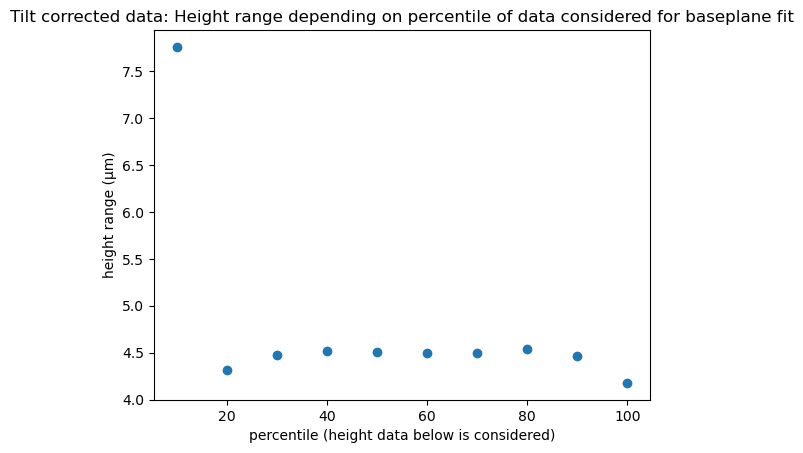

In [479]:
plt.plot(percentages, height_range, 'o')
plt.title('Tilt corrected data: Height range depending on percentile of data considered for baseplane fit')
plt.xlabel('percentile (height data below is considered)')
plt.ylabel('height range (µm)')
plt.show()

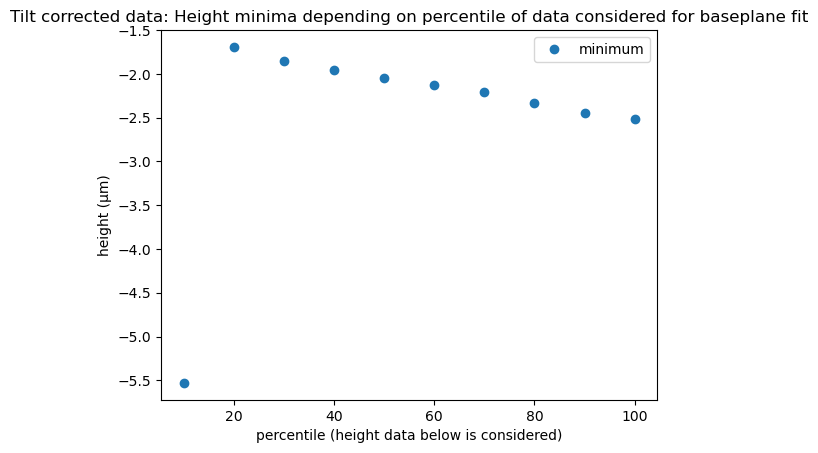

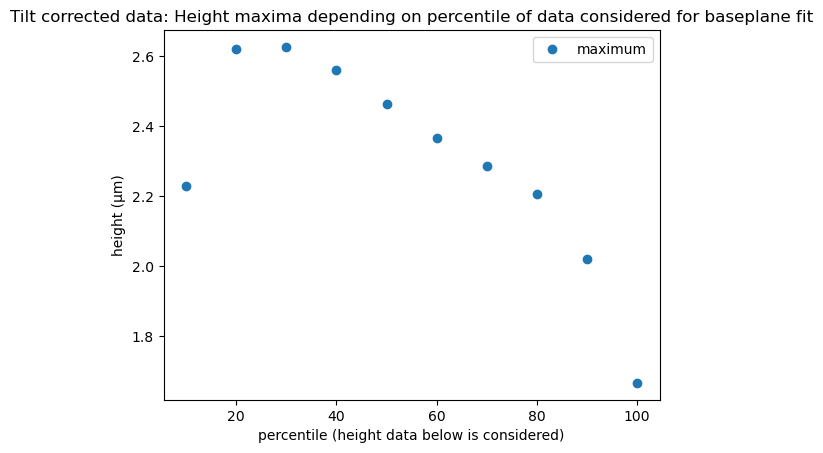

In [480]:
plt.plot(percentages, height_min, 'o', label='minimum')
plt.title('Tilt corrected data: Height minima depending on percentile of data considered for baseplane fit')
plt.xlabel('percentile (height data below is considered)')
plt.ylabel('height (µm)')
plt.legend()
plt.show()

plt.plot(percentages, height_max, 'o', label='maximum')
plt.title('Tilt corrected data: Height maxima depending on percentile of data considered for baseplane fit')
plt.xlabel('percentile (height data below is considered)')
plt.ylabel('height (µm)')
plt.legend()
plt.show()

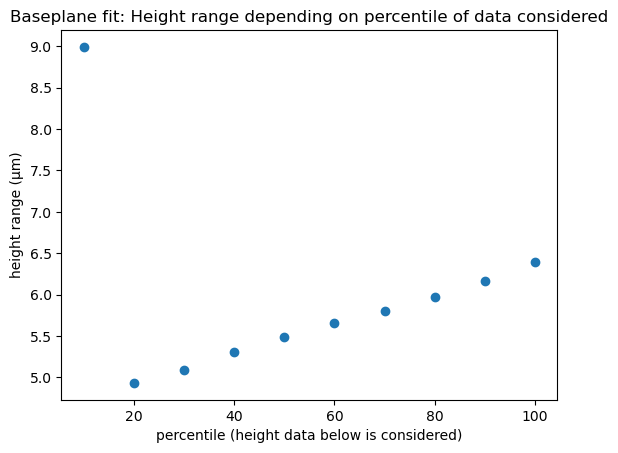

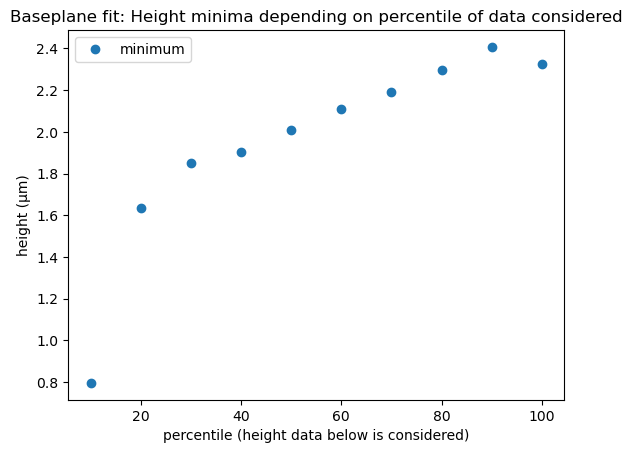

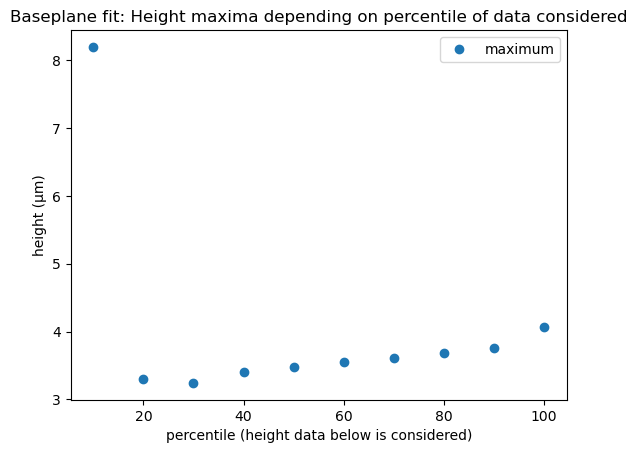

In [481]:
height_data_fit = []
height_min_fit = []
height_max_fit = []
height_range_fit = []

for percentage in percentages:
    data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, percentage)
    height_data_fit.append(np.array(data_1_vk4_tiltcorr['baseplane_fit'].flatten()))
    height_min_fit.append(np.min(data_1_vk4_tiltcorr['baseplane_fit']))
    height_max_fit.append(np.max(data_1_vk4_tiltcorr['baseplane_fit']))
    height_range_fit.append(np.max(data_1_vk4_tiltcorr['baseplane_fit']) + np.abs(np.min(data_1_vk4_tiltcorr['baseplane_fit'])))

plt.plot(percentages, height_range_fit, 'o')
plt.title('Baseplane fit: Height range depending on percentile of data considered')
plt.xlabel('percentile (height data below is considered)')
plt.ylabel('height range (µm)')
plt.show()

plt.plot(percentages, height_min_fit, 'o', label='minimum')
plt.title('Baseplane fit: Height minima depending on percentile of data considered')
plt.xlabel('percentile (height data below is considered)')
plt.ylabel('height (µm)')
plt.legend()
plt.show()

plt.plot(percentages, height_max_fit, 'o', label='maximum')
plt.title('Baseplane fit: Height maxima depending on percentile of data considered')
plt.xlabel('percentile (height data below is considered)')
plt.ylabel('height (µm)')
plt.legend()
plt.show()

Plane needs to be determined by pixels representing the normal salt surface and not by deep holes, edges, steep features, large structures.
Selecting the lower/higher percentages of pixels is not good, because a lot of those pixels could be inside holes/on elevations rather than representative of the salt surface -> fitted plane gets pulled down towards the holes, making the holes appear shallower after subtraction

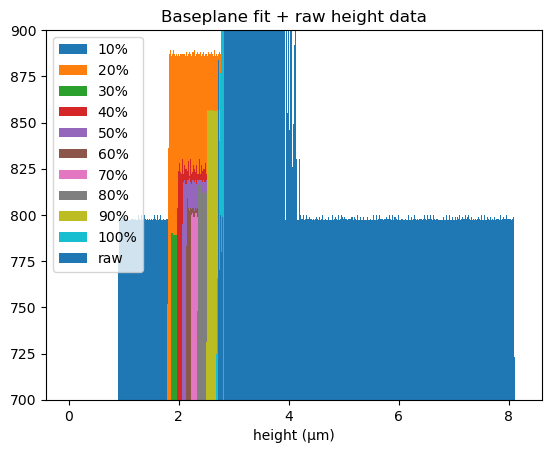

In [482]:
for percentage in percentages:
    data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, percentage)   
    plt.hist(data_1_vk4_tiltcorr['baseplane_fit'].flatten(), bins=1000, label=f'{percentage}%')

plt.hist(data_1_vk4['img_height_data']['data'].flatten(), bins=1000, label='raw')
plt.xlabel('height (µm)')
plt.title('Baseplane fit + raw height data')
plt.legend()
plt.ylim(700, 900)
plt.show()

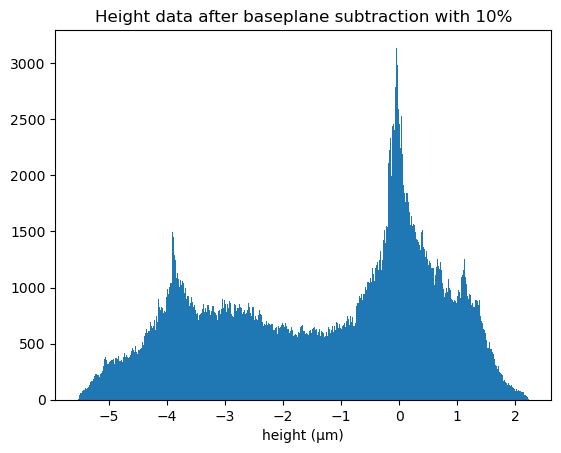

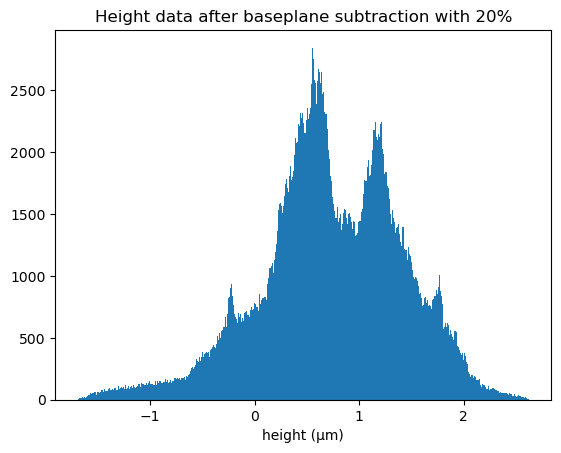

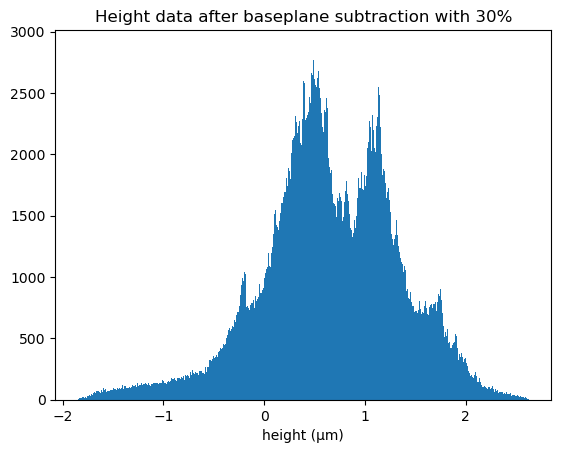

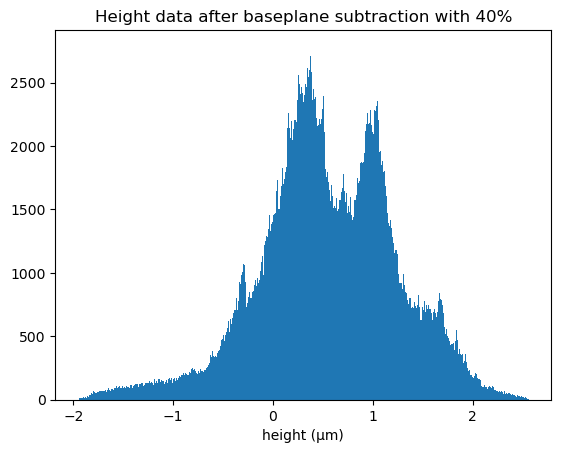

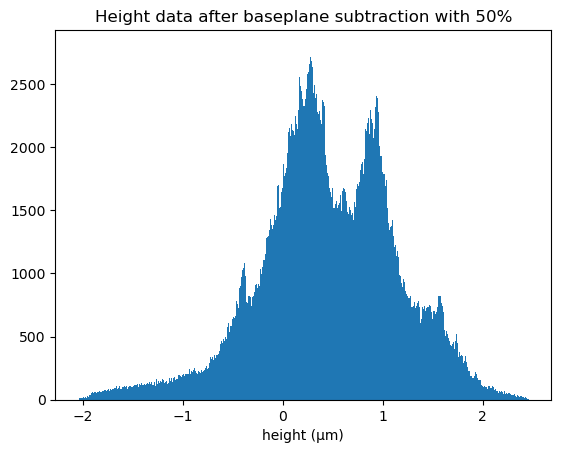

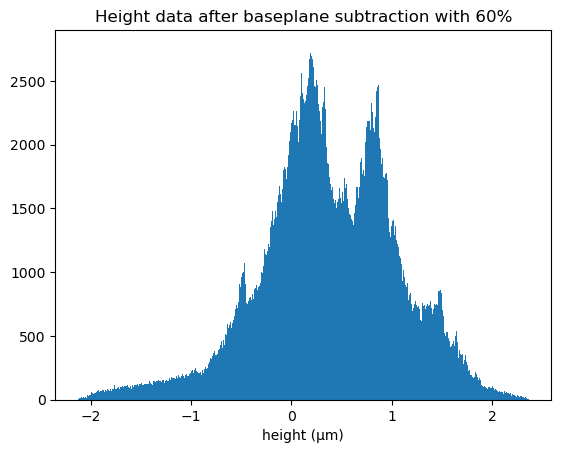

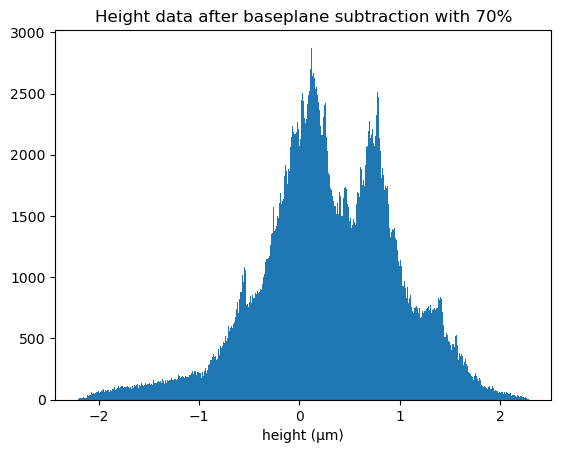

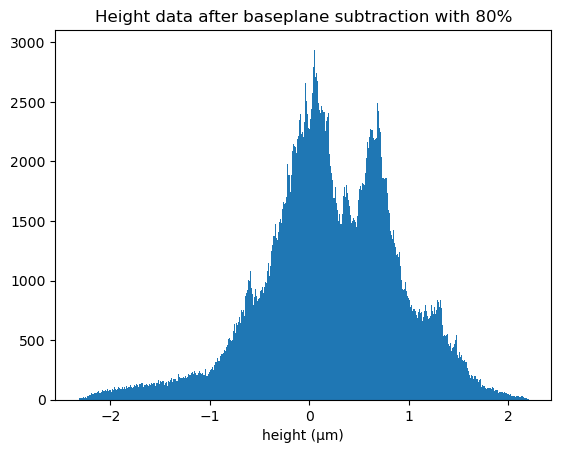

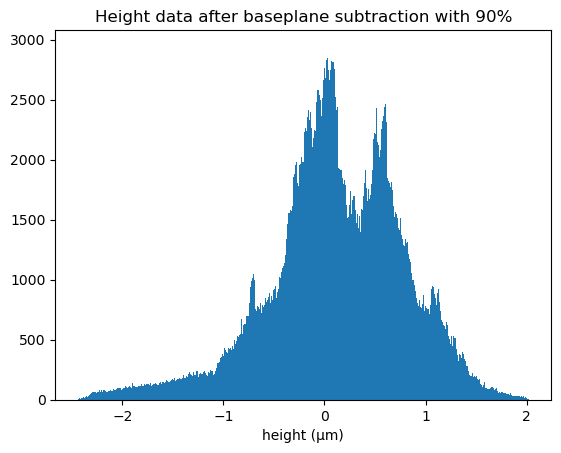

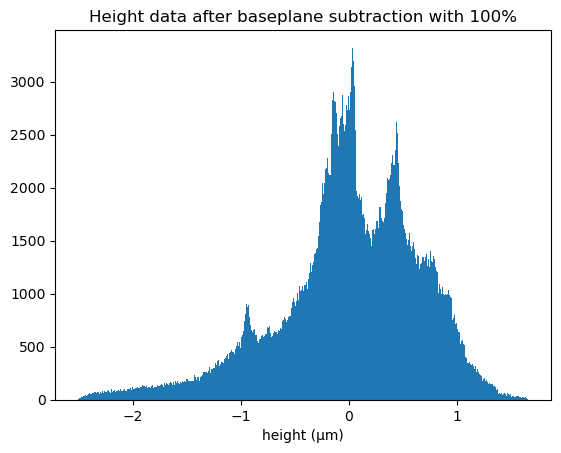

In [483]:
for data, percentage in zip(height_data, percentages):
    plt.hist(data, bins=1000)
    plt.xlabel('height (µm)' )
    plt.title(f'Height data after baseplane subtraction with {percentage}%')
    plt.show()

**Current status**

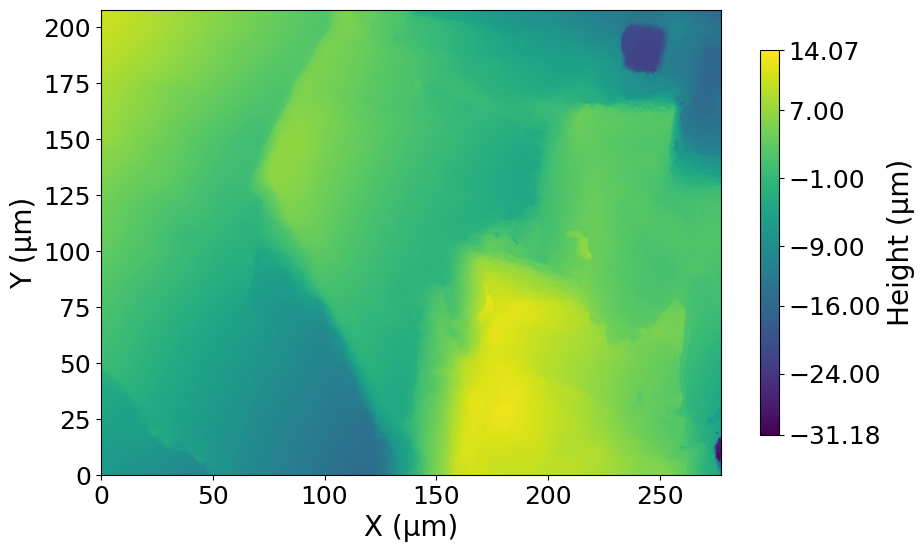

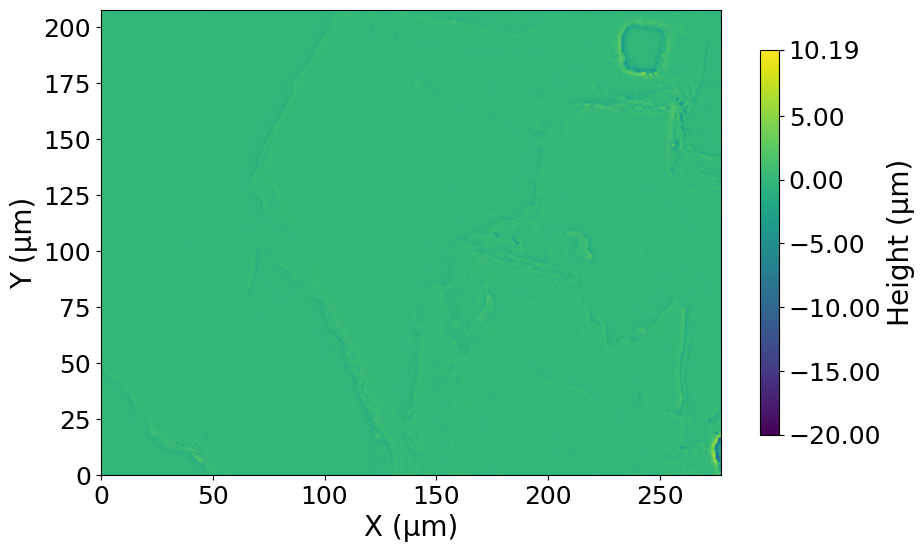

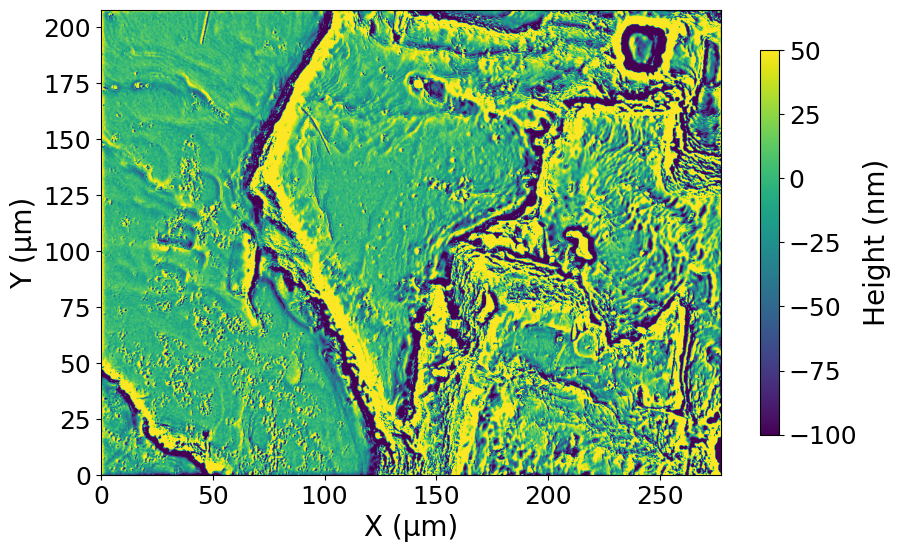

In [562]:
data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, 100)
data_1_vk4_enhanced = gaussian_filter_height(data_1_vk4_tiltcorr, 5)
data_1_vk4_clipped = feature_enhancement_proceedings(data_1_vk4_enhanced)

ax = plot_vk4_height(data_1_vk4_clipped, data_type='baseplane_subtracted')
ax = plot_vk4_height(data_1_vk4_clipped, data_type='gaussian_filtered')
ax = plot_vk4_height(data_1_vk4_clipped, data_type='feature_enhanced')

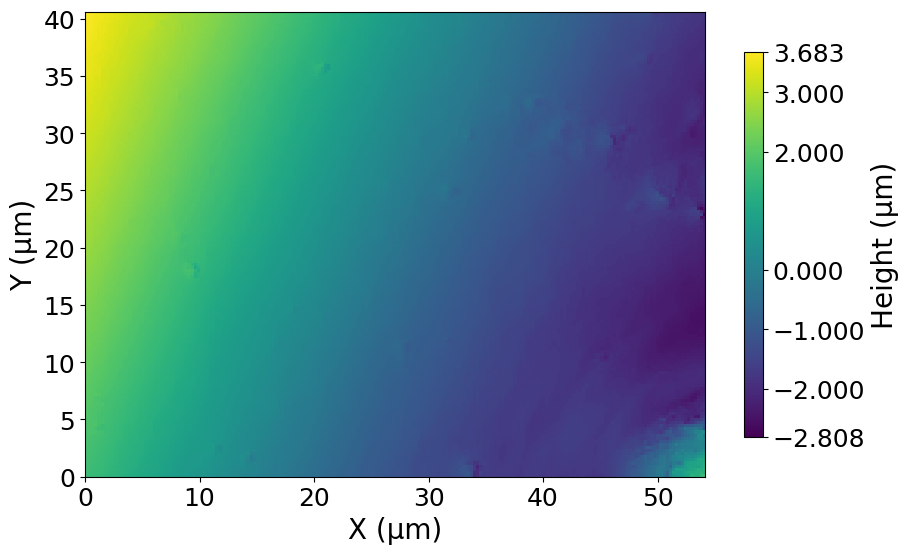

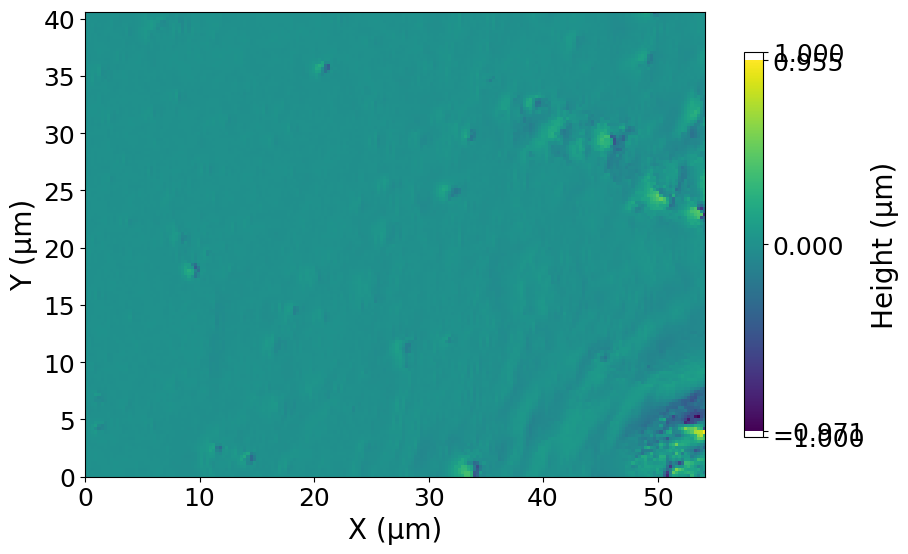

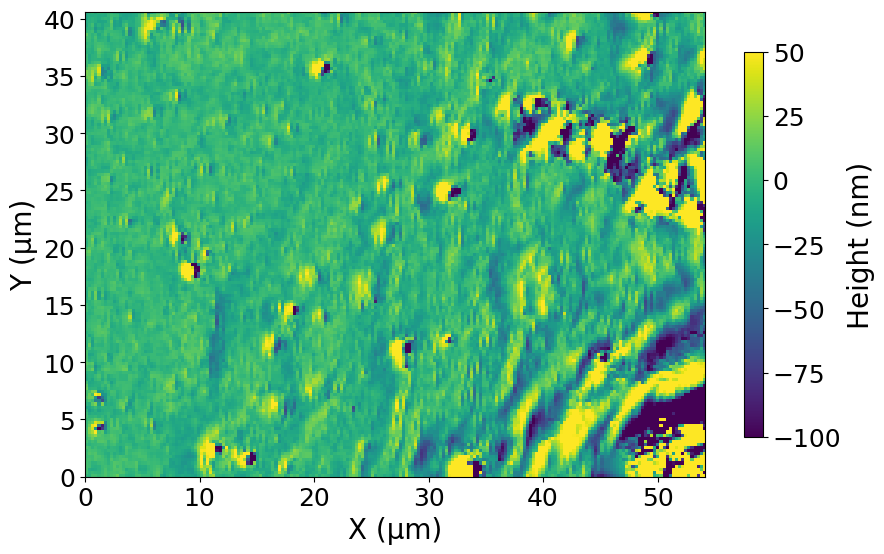

In [ ]:
crop = crop_Vk4File_map(data_1_vk4, x0=300, x1=650, y0=400, y1=650)
ax = plot_vk4_height(crop, data_type='baseplane_subtracted')
ax = plot_vk4_height(crop, data_type='gaussian_filtered')
ax = plot_vk4_height(crop, data_type='feature_enhanced')

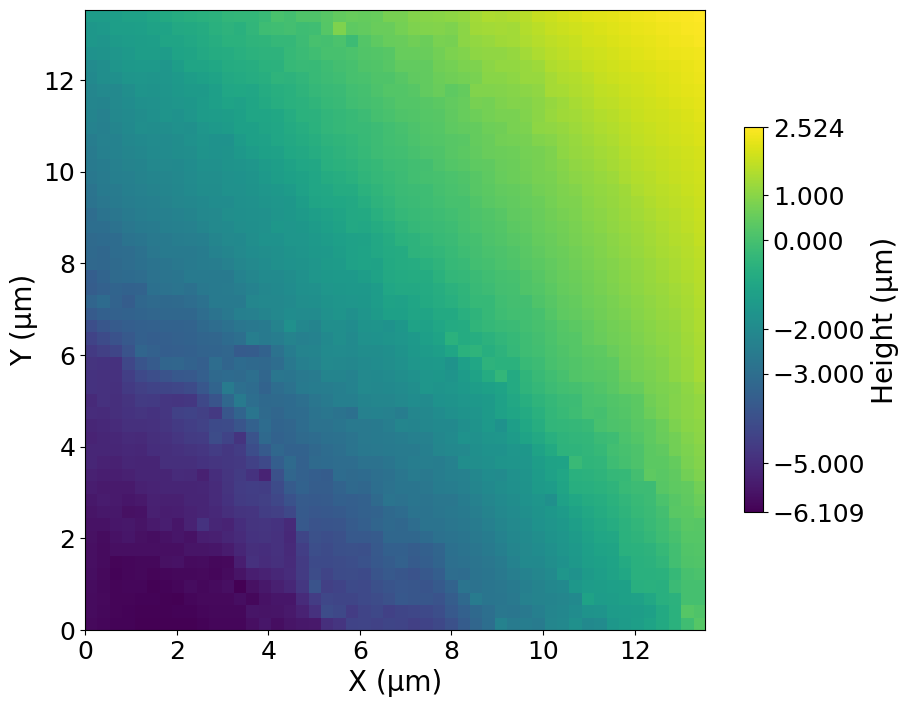

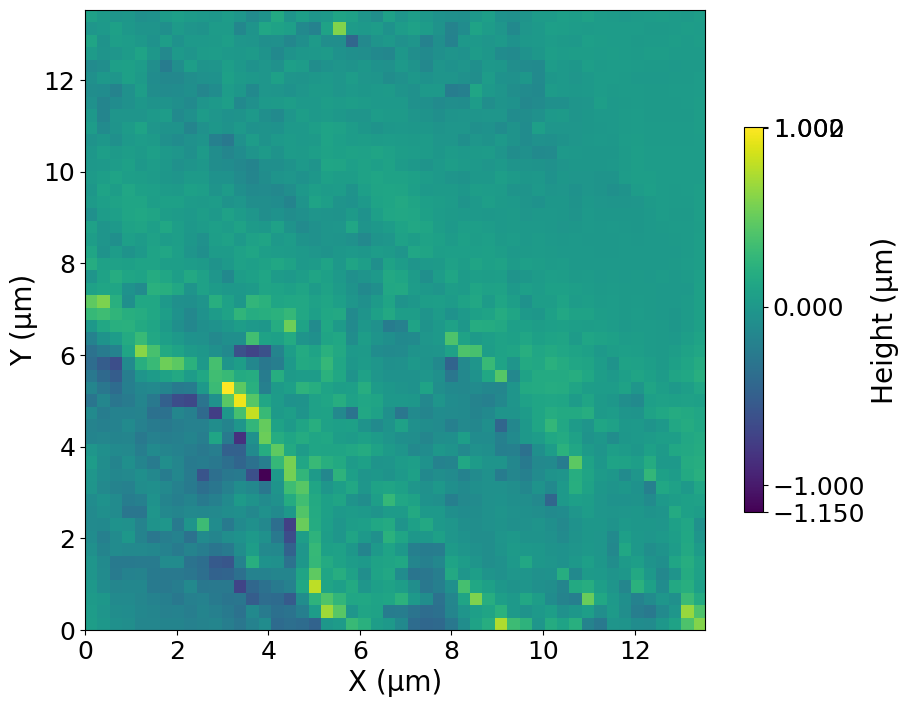

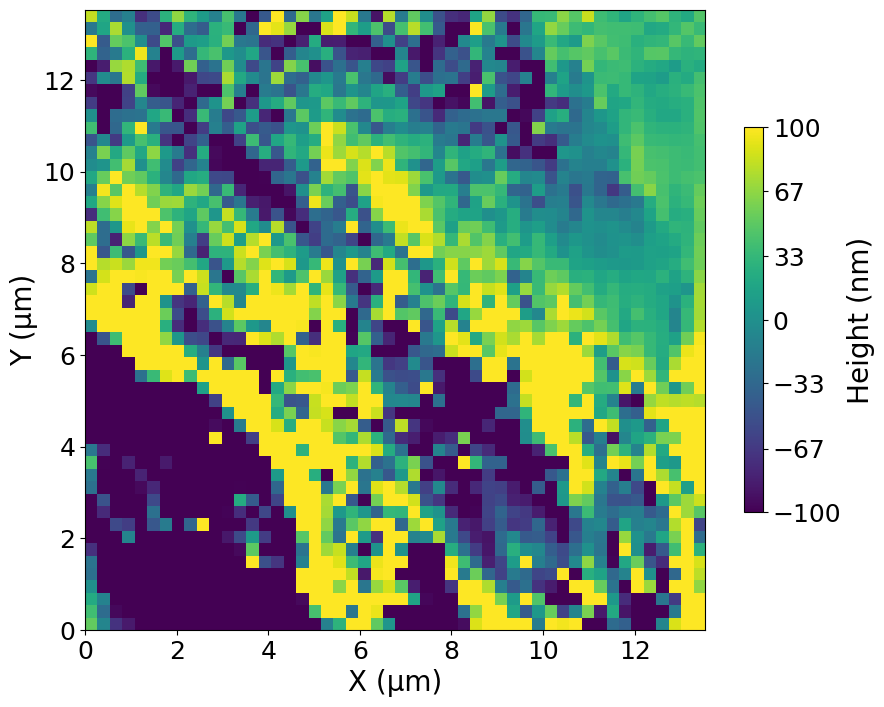

In [561]:
crop2 = crop_Vk4File_map(data_1_vk4, x0=300, x1=350, y0=400, y1=450)
ax = plot_vk4_height(crop2, data_type='baseplane_subtracted')
ax = plot_vk4_height(crop2, data_type='gaussian_filtered')
ax = plot_vk4_height(crop2, data_type='feature_enhanced')

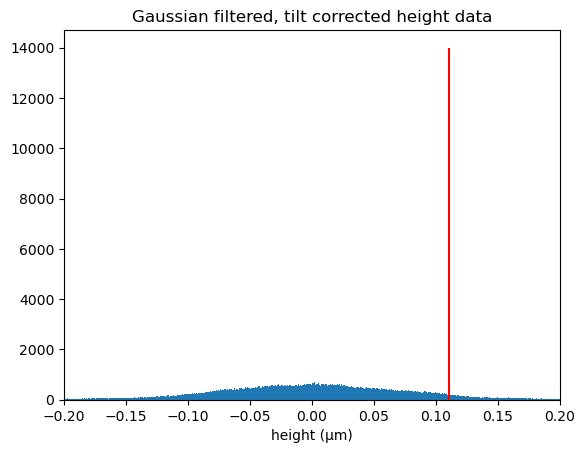

In [511]:
plt.hist(data_1_vk4_enhanced['gaussian_filtered'].flatten(), bins=10000)
plt.xlim(-0.2, 0.2)
p_low1, p_high1 = np.percentile(data_1_vk4_enhanced['feature_enhanced'].flatten(), (0.5, 90))
plt.vlines(p_low1, 0, 14000, 'red')
plt.vlines(p_high1, 0, 14000, 'red')
plt.title('Gaussian filtered, tilt corrected height data')
plt.xlabel('height (µm)')
plt.show()

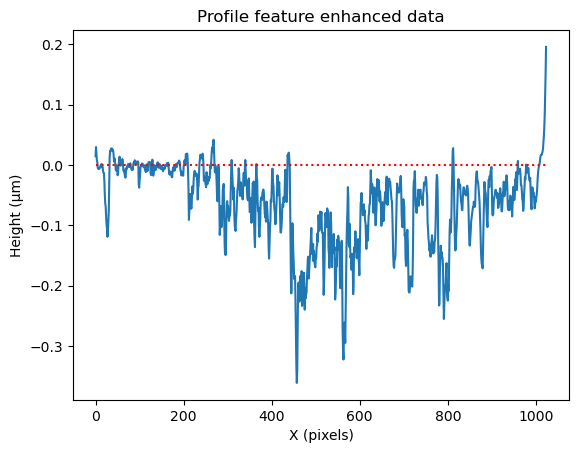

In [539]:
reshaped = reshape_img_data(data_1_vk4_enhanced, data_type='feature_enhanced')
profile_processed = np.mean(reshaped, axis=0)
x_pixels = reshaped.shape[1]
plt.plot(range(x_pixels), profile_processed)
    
plt.xlabel('X (pixels)')
plt.ylabel('Height (µm)')
plt.title('Profile feature enhanced data')
plt.hlines(0, 0, 1024, 'red', 'dotted')
plt.show()

**Histograms of height data**

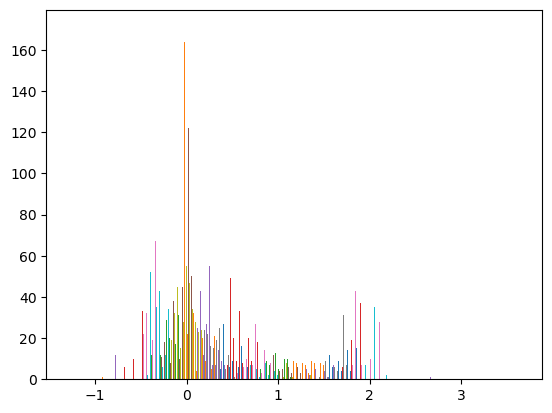

In [ ]:
# cell takes 3 min  
data_processed = data_1_vk4_tiltcorr['baseplane_subtracted']
plt.hist(data_processed, bins=100)
plt.show()

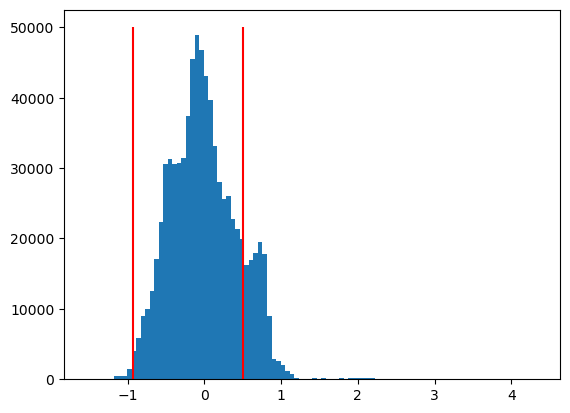

In [272]:
data_processed = data_1_vk4_tiltcorr['baseplane_subtracted'].flatten()
plt.hist(data_processed, bins=100)
p_low, p_high = np.percentile(data_processed, (0.5, 85))
plt.vlines(p_low, 0, 50000, 'red')
plt.vlines(p_high, 0, 50000, 'red')
plt.show()

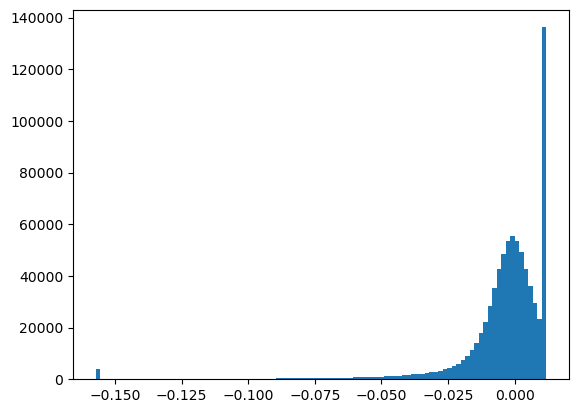

In [330]:
data_enhanced = data_1_vk4_enhanced['feature_enhanced'].flatten()
plt.hist(data_enhanced, bins=100)
plt.show()

**Optical image for reference**

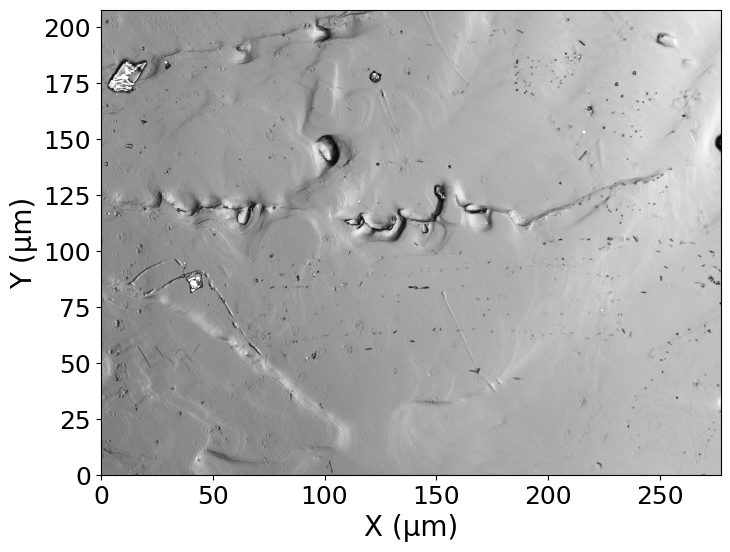

In [258]:
ax = plot_vk4_reflected_light(data_1_vk4)

**Use new clip percentiles determined from histogram\
Clipping lower end necessary because deep holes dominate height bar and small features disappear -> if we have estimates of how deep features/etch pits are cutting away everything deeper is justified right?** 

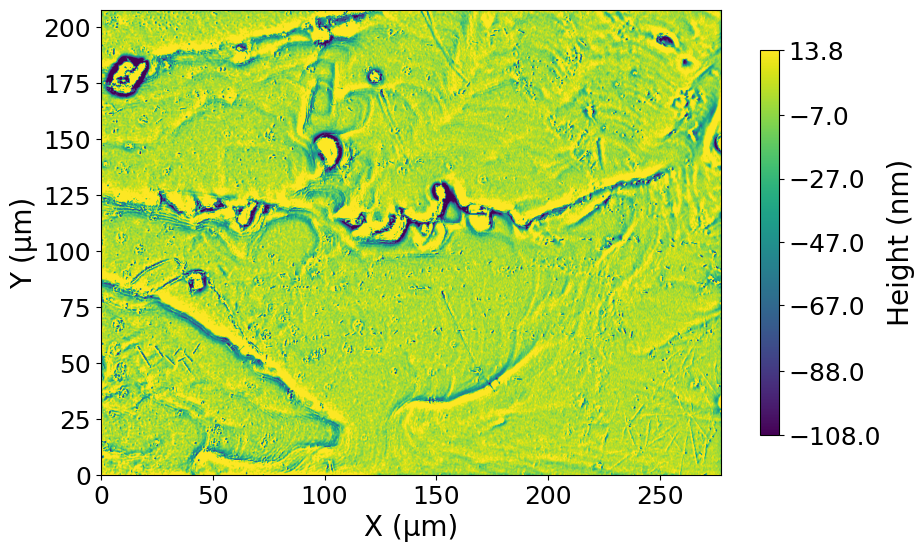

In [103]:
data_1_vk4_enhanced = feature_enhancement_single_gaussian_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

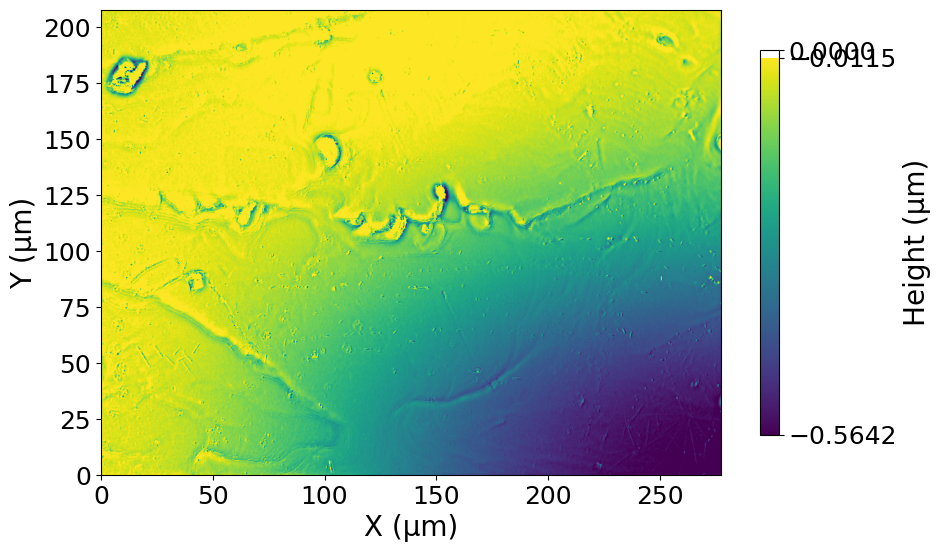

In [110]:
data_1_vk4_enhanced = feature_enhancement_double_gaussian_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

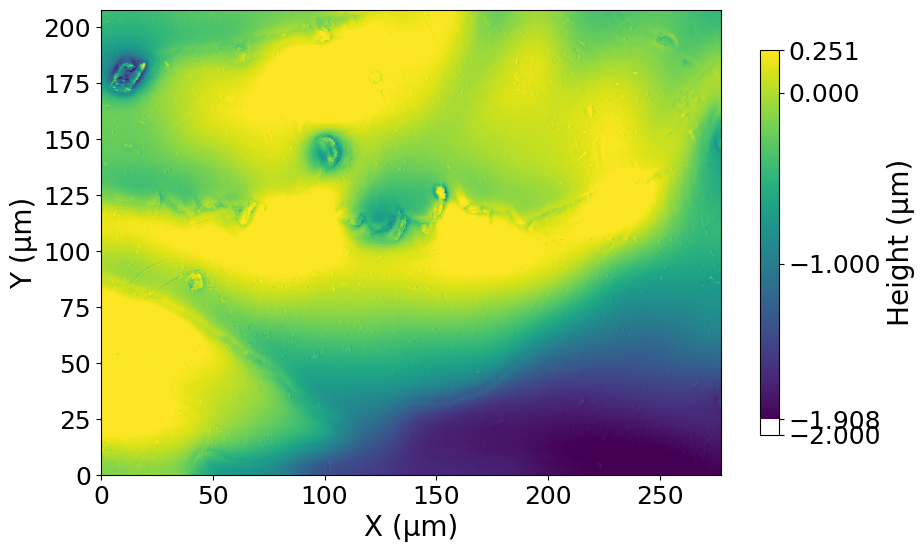

In [108]:
data_1_vk4_enhanced = feature_enhancement_triple_gaussian_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

**Instead of clipping set height values above and beneath the percentiles to median**

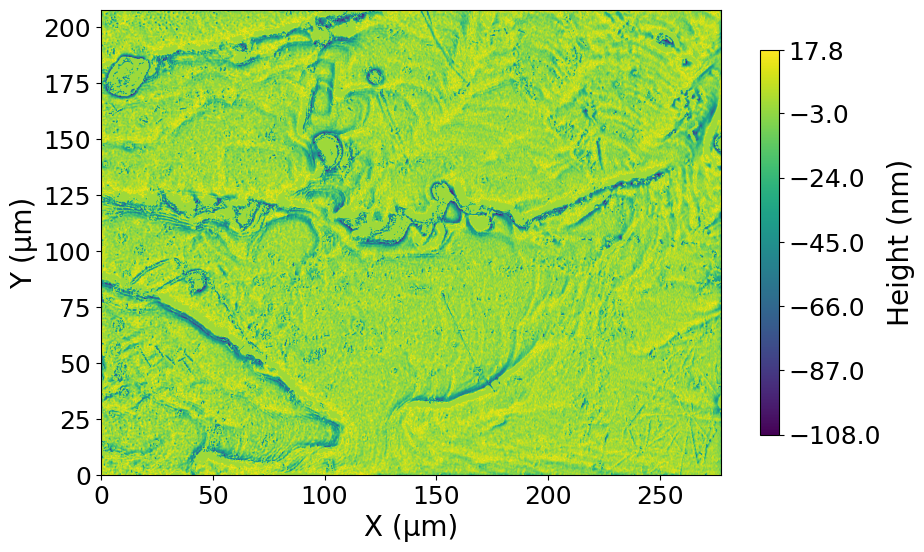

In [444]:
data_1_vk4_enhanced = feature_enhancement_single_gaussian_median_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

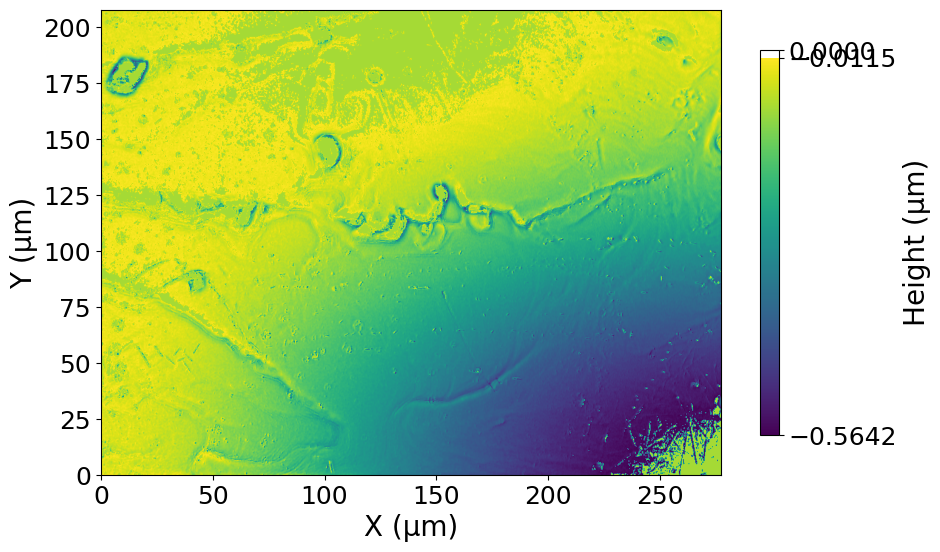

In [114]:
data_1_vk4_enhanced = feature_enhancement_double_gaussian_median_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

**Single gaussian filter with sigma=5 from now on\
Usolved mystery: why clipping height on both ends makes height range bigger compared to only clipping upper end? (compare with feature_enhancement_single_gaussian_median_clip)**

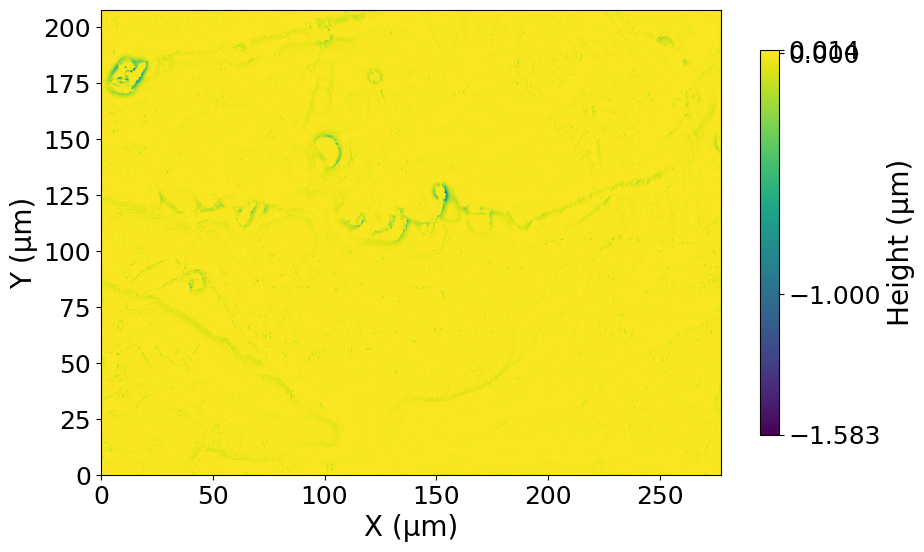

In [115]:
data_1_vk4_enhanced = feature_enhancement_median_clip_high(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

**Best result so far imho because small holes are very distinct compared to background\
Setting everything above baseplane (which should be at 0) to 0 should not distort the proportions\
Cutting deep holes that are too deep to be features helps reduce height range\
Trade-off: range too small -> enhances features, but might lose some feature if you start cutting beneath 0; range too big -> features not visible because topography dominates**

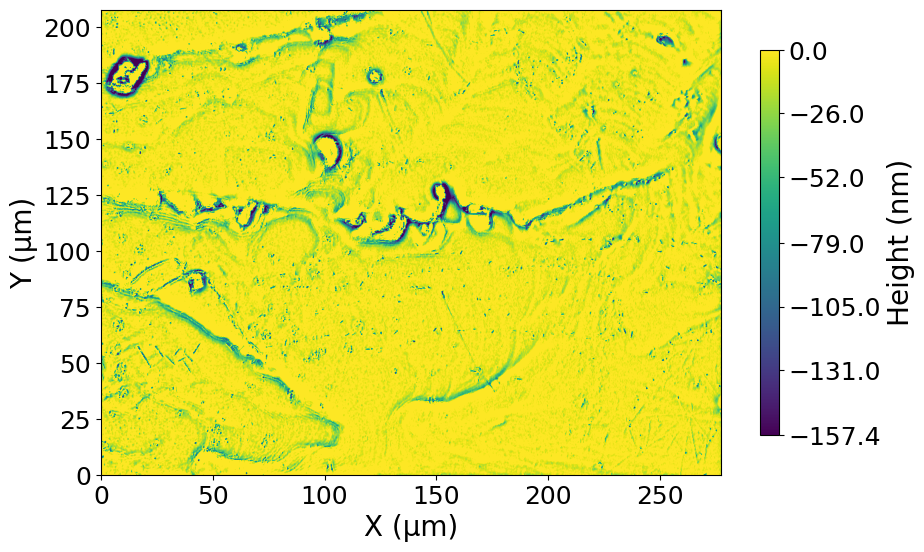

In [443]:
data_1_vk4_enhanced = feature_enhancement_cut_elevations_and_holes(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

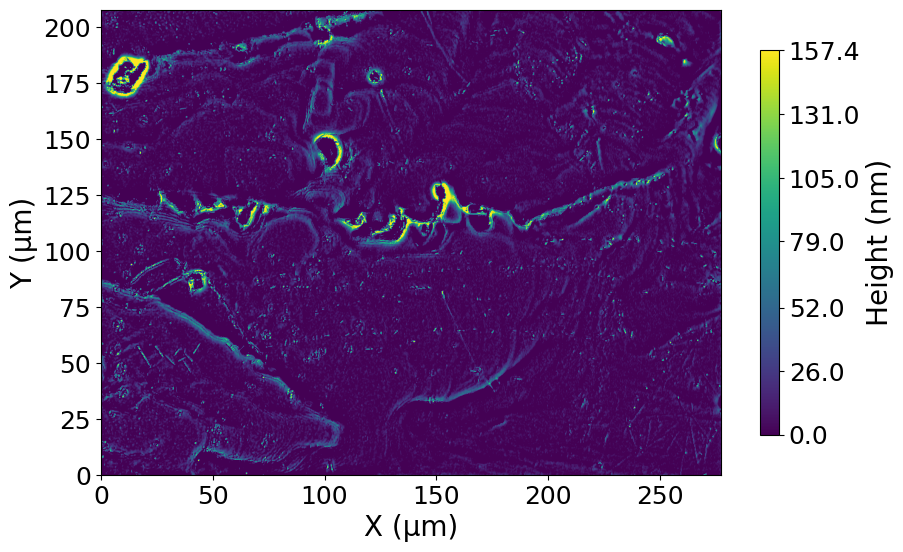

In [52]:
data_1_vk4_enhanced = feature_enhancement_cut_elevations_and_holes_2(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

**black_tophat from scikit-image, should enhance small dark holes; maybe good for ML but height values are of course not correct anymore**

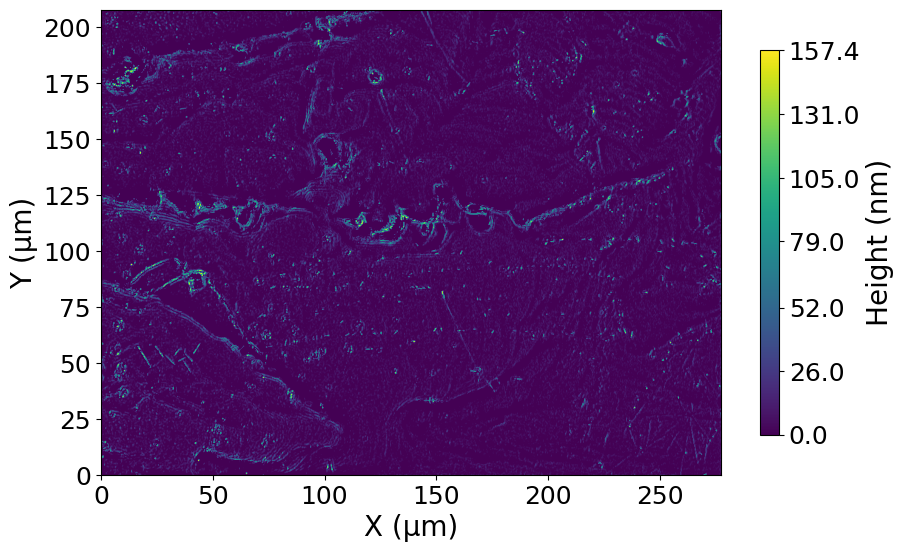

In [122]:
data_1_vk4_enhanced = feature_enhancement_morphological(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

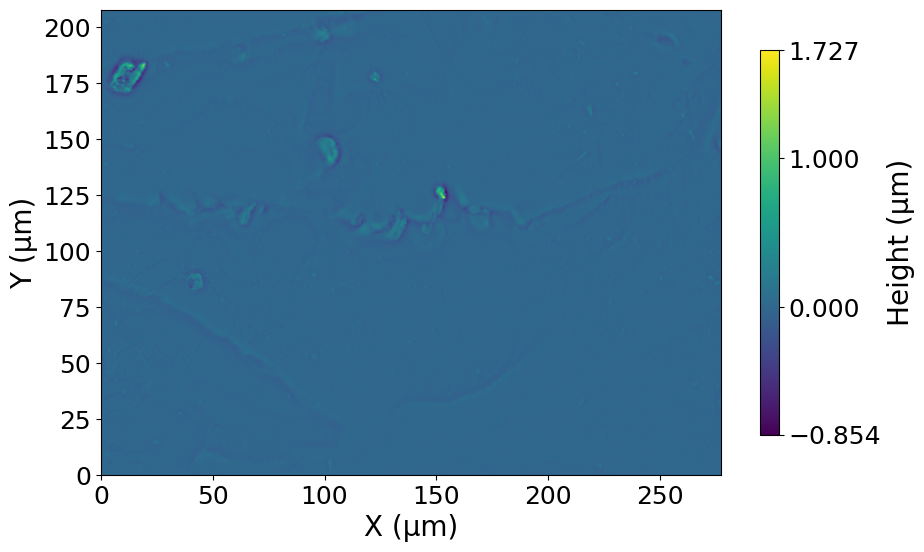

In [41]:
data_1_vk4_enhanced = feature_enhancement_diff_gaussians(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

In [7]:
data_1_vk4_enhanced = feature_enhancement_stretch_contrast(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

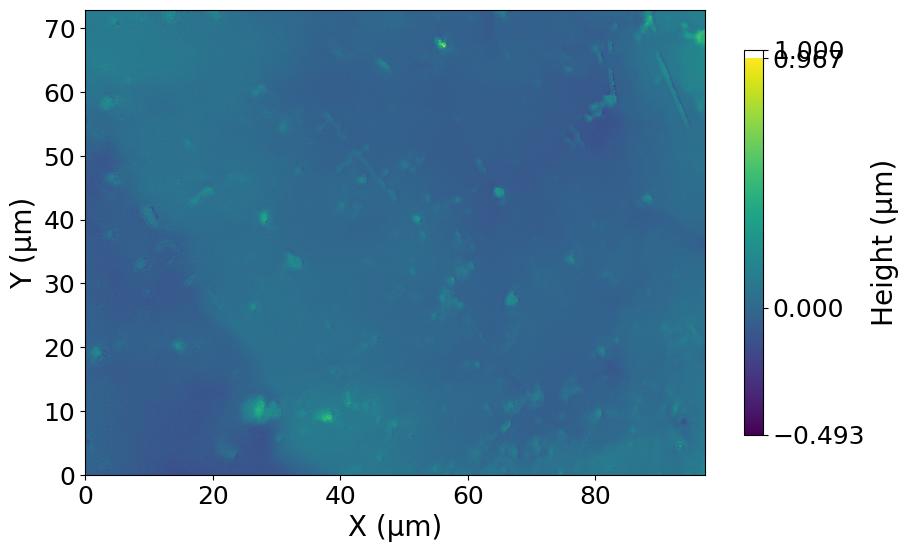

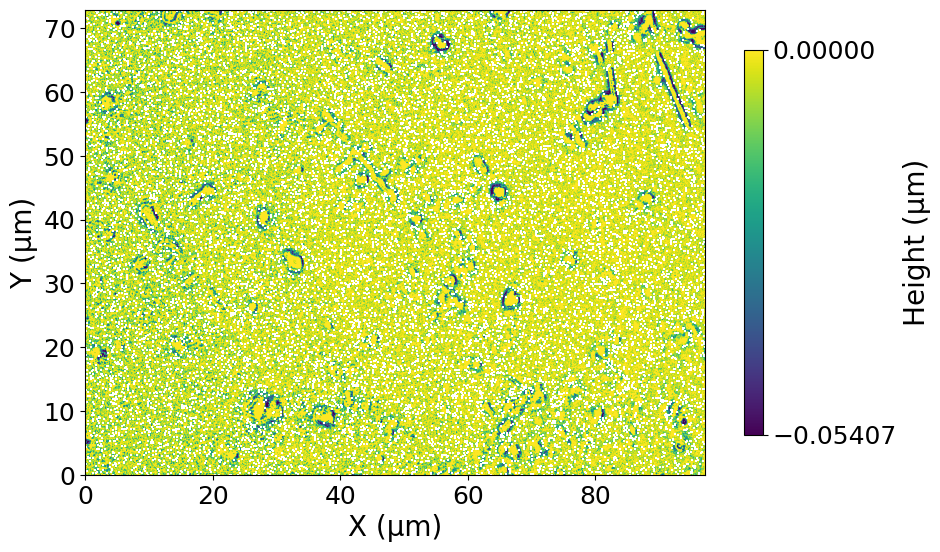

In [305]:
file_name4 = Path("../raw_data_vk/Sample 3 Milan full/Stitched 150x/20260619161302_Y4_X1.vk4")

with open(file_name4, 'rb') as f:
    data_4_vk4 = parse_vk4_file(f)

data_4_vk4_tiltcorr = baseplane_filter(data_4_vk4, 100)
data_4_vk4_enhanced = feature_enhancement_proceedings(data_4_vk4_tiltcorr)

ax = plot_vk4_height(data_4_vk4_enhanced, data_type='baseplane_subtracted')
ax = plot_vk4_height(data_4_vk4_enhanced, data_type='feature_enhanced')

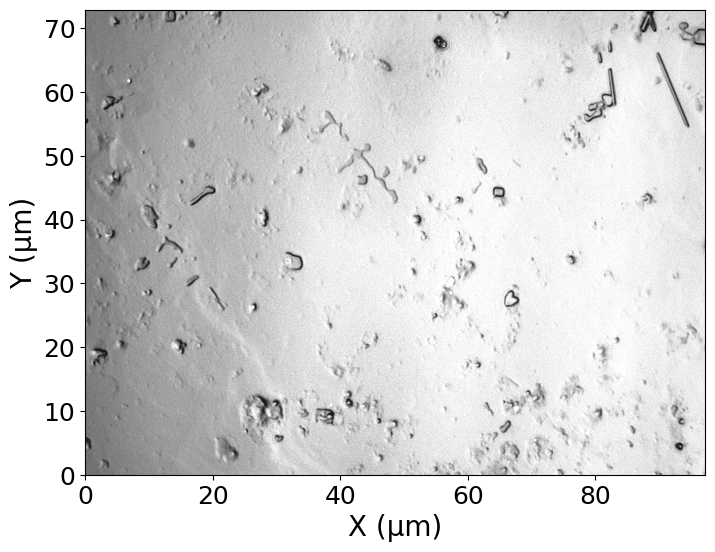

In [167]:
ax = plot_vk4_reflected_light(data_4_vk4)

**Why is there almost always an elevated area next to hole?**

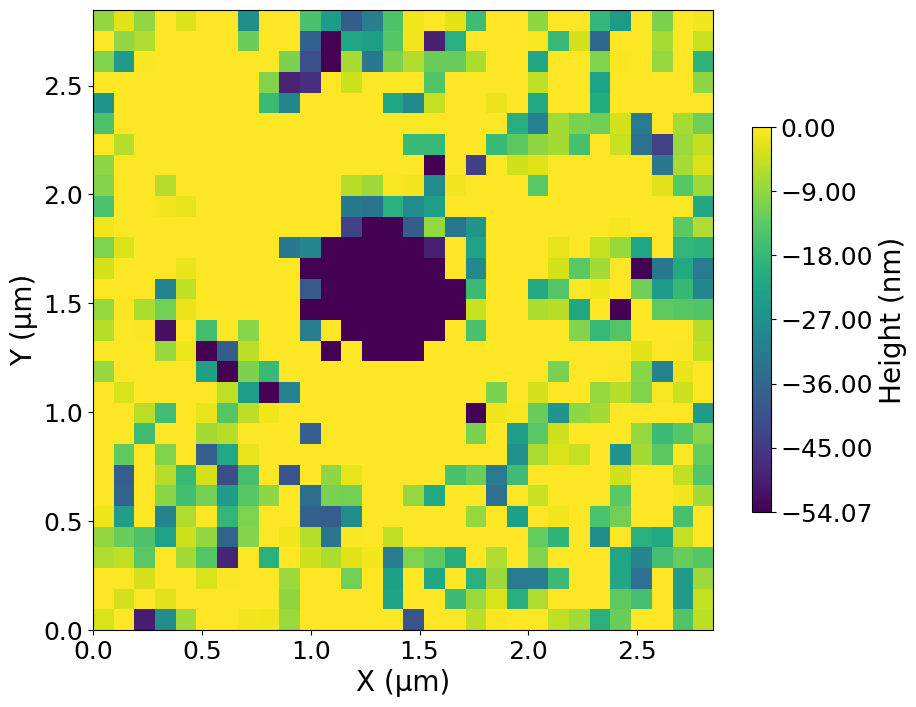

In [283]:
cropped = crop_Vk4File_map(data_4_vk4_enhanced, x0=40, x1=70, y0=10, y1=40)


ax = plot_vk4_height(cropped, data_type='feature_enhanced')
#plt.savefig('small feature.jpeg')
#plt.plot()

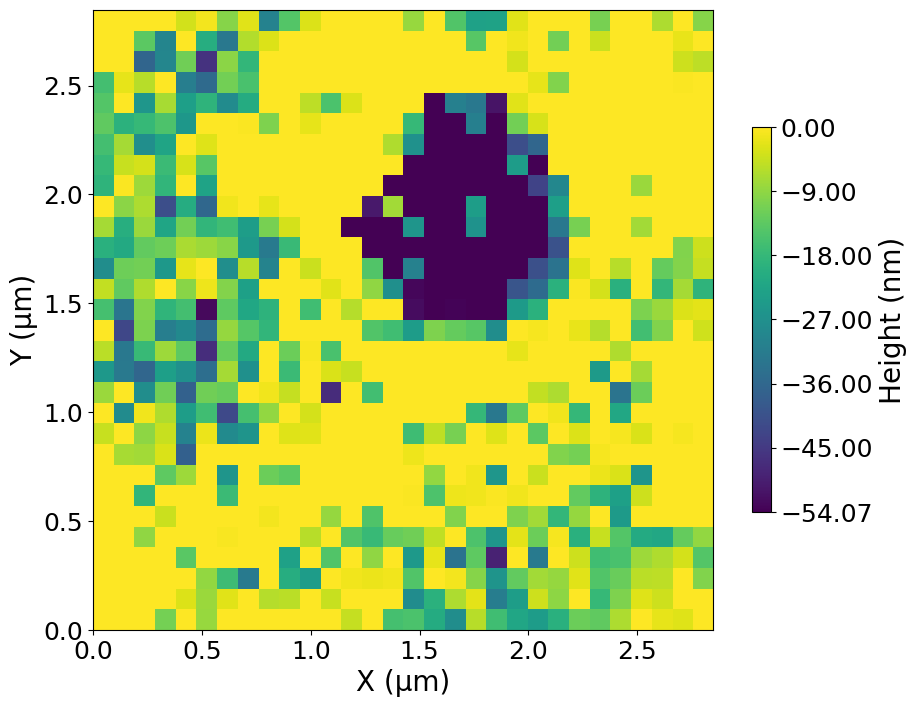

In [284]:
cropped = crop_Vk4File_map(data_4_vk4_enhanced, x0=970, x1=1000, y0=670, y1=700)


ax = plot_vk4_height(cropped, data_type='feature_enhanced')

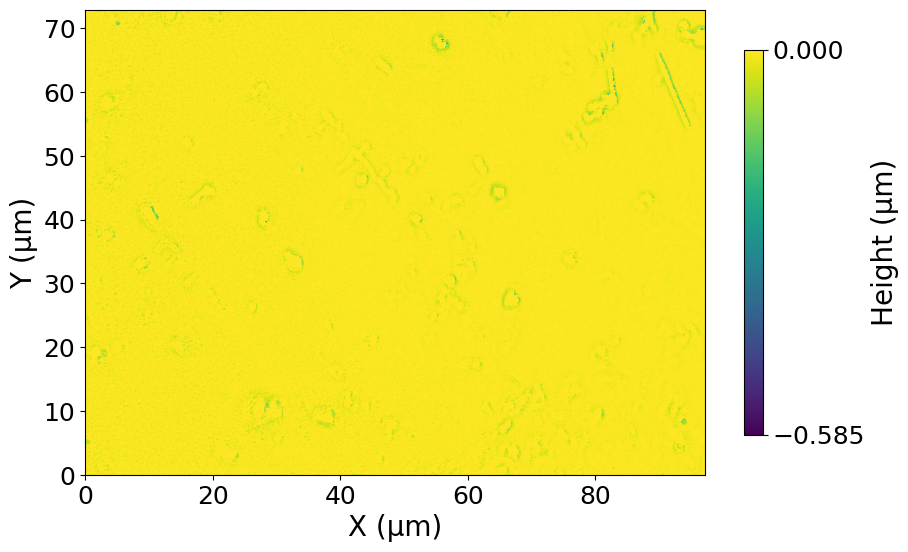

In [285]:
data_4_vk4_enhanced_2 = feature_enhancement_cut_elevations_and_holes(data_4_vk4_tiltcorr)

ax = plot_vk4_height(data_4_vk4_enhanced_2, data_type='feature_enhanced')

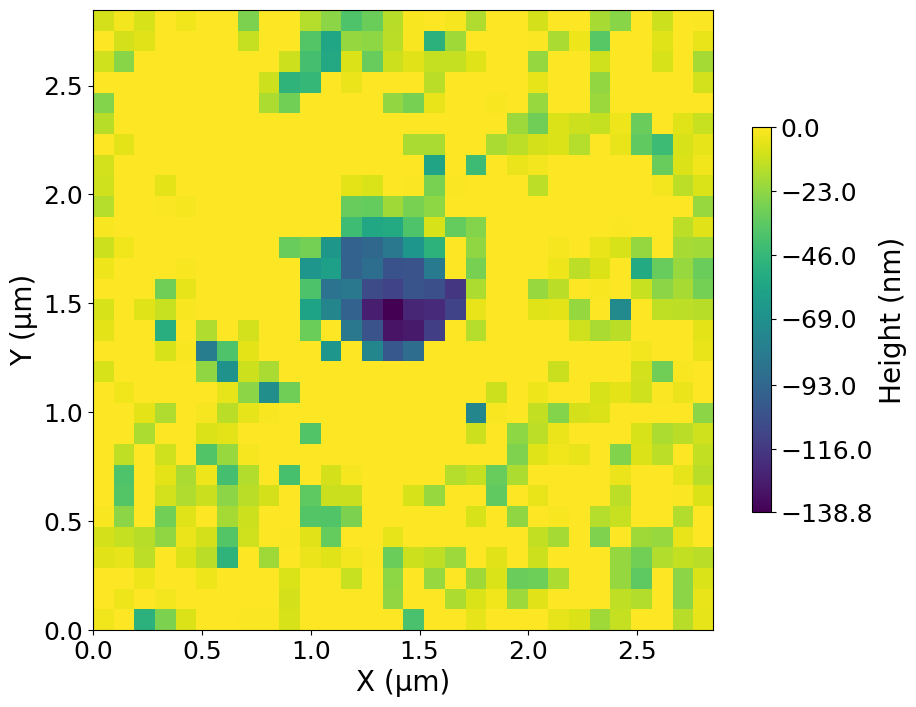

In [286]:
cropped_2 = crop_Vk4File_map(data_4_vk4_enhanced_2, x0=40, x1=70, y0=10, y1=40)


ax = plot_vk4_height(cropped_2, data_type='feature_enhanced')

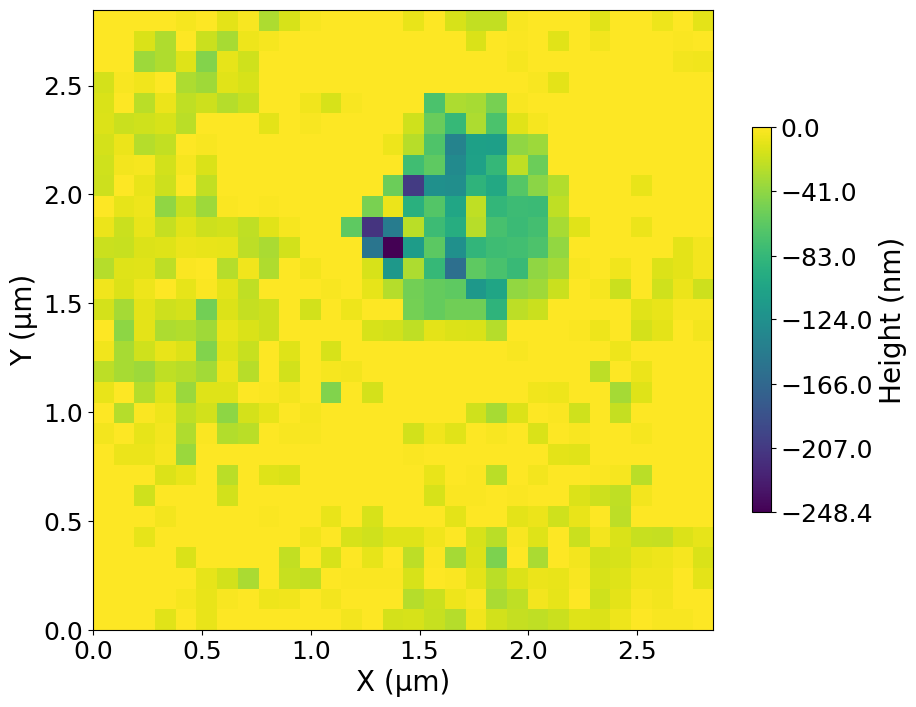

In [287]:
cropped_2 = crop_Vk4File_map(data_4_vk4_enhanced_2, x0=970, x1=1000, y0=670, y1=700)


ax = plot_vk4_height(cropped_2, data_type='feature_enhanced')